# Projet 3 — WESAD : stress et capteurs portables
### Inférence causale, apprentissage machine et apprentissage profond

**Auteur :** Mohamed Chouraki
**Jeu de données :** WESAD (Wearable Stress and Affect Detection)
**Lien du jeu de données :** https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection
**Date de téléchargement :** 5 juillet 2026

**Organisation du notebook :** ce notebook suit exactement l'ordre des 6 questions du barème :
1. Exploration du jeu de données et choix des algorithmes
2. Prétraitement temporel et création des variables dérivées
3. Modèles prédictifs et apprentissage profond
4. Formulation de la question causale
5. Estimation causale (arbre/forêt causale) et comparaison
6. Interprétation, conclusion et qualité du notebook

**Reproductibilité :** placez le dossier `WESAD/` (tel qu'obtenu en dézippant `WESAD.zip`) au même niveau que ce notebook,
de façon à avoir la structure `./WESAD/S2/S2.pkl`, `./WESAD/S3/S3.pkl`, etc. Aucune autre intervention manuelle n'est nécessaire.


---
## Question 1 — Exploration du jeu de données et choix des algorithmes (15 points)

### 1.0 Choix du sous-ensemble de sujets et de modalités (à annoncer avant l'analyse)

WESAD contient 15 sujets (S1 est absent des données publiées, donc en pratique S2 à S17, soit 15 fichiers).
Le jeu de données complet est volumineux (chaque sujet ≈ 1 heure de signaux à 700 Hz pour la poitrine), donc conformément
à la consigne, **j'annonce ici mon sous-ensemble avant de commencer l'analyse** :

- **Sujets retenus :** `SUBJECTS` défini ci-dessous (par défaut tous les sujets disponibles ; réduisez la liste si le temps de calcul est trop long sur votre machine).
- **Modalités retenues :** capteur **poitrine (chest)** à 700 Hz — ECG, EDA, EMG, Temp, Resp, ACC — car il s'agit du signal
  le plus complet et le mieux synchronisé (une seule fréquence pour toutes les modalités). Le poignet (wrist, Empatica E4)
  est utilisé en complément pour EDA/BVP/TEMP à titre de comparaison, mais avec des fréquences différentes (4 à 64 Hz),
  ce qui demande une synchronisation séparée expliquée en Question 2.
- **Justification :** utiliser la poitrine comme base commune de fenêtrage évite d'avoir à ré-échantillonner plusieurs
  fréquences différentes pour construire les variables principales, ce qui réduit le risque d'erreurs de synchronisation
  tout en gardant un jeu de données représentatif (5 modalités physiologiques + mouvement).


In [1]:
# --- Installation automatique des dependances non standard (si absentes) ---
# Garantit une execution de bout en bout sans intervention manuelle (consigne de reproductibilite).
import importlib
import subprocess
import sys

_REQUIRED_PACKAGES = {
    "xgboost": "xgboost",
    "torch": "torch",
    "econml": "econml",
    "networkx": "networkx",
    "statsmodels": "statsmodels",
    "sklearn": "scikit-learn",
}
for _module_name, _pip_name in _REQUIRED_PACKAGES.items():
    if importlib.util.find_spec(_module_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip_name])

# --- Importations ---
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)  # ne pas tronquer le texte dans les tableaux affiches

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Configuration ---
DATA_DIR = "WESAD"  # chemin relatif : le dossier WESAD/ doit être placé à côté de ce notebook

# Sous-ensemble de sujets utilisé pour l'analyse (annoncé et justifié ci-dessus).
# Modifiez cette liste si vous voulez réduire le temps de calcul.
SUBJECTS = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17]  # S12 est parfois absent/corrompu selon la version du zip

FREQ_CHEST = 700  # Hz, identique pour toutes les modalités de la poitrine
FREQ_WRIST = {"ACC": 32, "BVP": 64, "EDA": 4, "TEMP": 4}  # Hz, Empatica E4 au poignet

LABEL_MAP = {
    0: "transition_non_defini",
    1: "baseline",
    2: "stress",
    3: "amusement",
    4: "meditation",
    5: "autre_5",
    6: "autre_6",
    7: "autre_7",
}

print(f"Nombre de sujets prévus dans l'analyse : {len(SUBJECTS)}")


Nombre de sujets prévus dans l'analyse : 15


### 1.0bis Comprendre le dossier de données `WESAD/` (avant de charger quoi que ce soit)

Avant d'explorer les signaux eux-mêmes, il faut savoir ce que contient le dossier de données. Une fois
`WESAD.zip` dézippé, chaque sujet `SX` (X = numéro du sujet) a son propre sous-dossier avec 5 fichiers,
décrits dans `wesad_readme.pdf` fourni avec le dataset :

| Fichier | Contenu | Utilisé dans ce notebook ? |
|---|---|---|
| `SX_readme.txt` | Informations sur le sujet et la qualité de l'enregistrement | Non (lecture manuelle seulement) |
| `SX_quest.csv` | Protocole expérimental (horaires des conditions) et réponses aux questionnaires (PANAS, STAI, SAM, SSSQ) | Non (les labels sont tirés directement de `SX.pkl`) |
| `SX_respiban.txt` | Données brutes **non converties** du capteur de poitrine RespiBAN, à 700 Hz | Non (valeurs déjà converties dans `SX.pkl`) |
| `SX_E4_Data.zip` | Données brutes du bracelet Empatica E4 (poignet), **non synchronisées** avec la poitrine | Non (déjà synchronisées dans `SX.pkl`) |
| `SX.pkl` | **Dictionnaire Python** avec les signaux poitrine + poignet déjà synchronisés dans le temps, et le label du protocole à 700 Hz | **Oui — seul fichier chargé par ce notebook** |

**Pourquoi seulement `SX.pkl` ?** La poitrine (RespiBAN, 700 Hz) et le poignet (Empatica E4, 4 à 64 Hz selon
le capteur) sont deux appareils différents qui ne démarrent pas exactement au même instant. Les auteurs du
dataset ont déjà réalisé la synchronisation manuelle (à l'aide d'un tapotement caractéristique détectable sur
les deux appareils, voir le readme officiel) et fournissent le résultat directement dans `SX.pkl`. Reprendre
cette synchronisation nous-mêmes referait un travail déjà fait, avec un risque d'erreur inutile pour ce projet.

On vérifie d'abord concrètement ce qu'il y a sur disque, puis on explique la signification physiologique de
chaque signal réellement utilisé.

In [2]:
# --- Verification concrete du contenu du dossier de donnees pour un sujet ---
sample_subject_dir = os.path.join(DATA_DIR, f"S{SUBJECTS[0]}")
files_in_folder = sorted(os.listdir(sample_subject_dir))
folder_df = pd.DataFrame({"fichier": files_in_folder})
folder_df["taille_Mo"] = [round(os.path.getsize(os.path.join(sample_subject_dir, f)) / 1e6, 1)
                            for f in files_in_folder]
folder_df

,fichier,taille_Mo
0,S2.pkl,975.1
1,S2_E4_Data.zip,1.8
2,S2_quest.csv,0.0
3,S2_readme.txt,0.0
4,S2_respiban.txt,261.3


In [3]:
# --- Tableau de signification des signaux (source : wesad_readme.pdf, officiel du dataset) ---
signal_meaning = pd.DataFrame([
    ["chest", "ECG",  "700 Hz", "mV",    "Activite electrique du coeur : sert a estimer la frequence et la "
     "variabilite cardiaques, un marqueur classique de l'activation du systeme nerveux autonome."],
    ["chest", "EDA",  "700 Hz", "uS",    "Activite electrodermale (conductance de la peau) : augmente avec la "
     "sudation liee a l'activation sympathique -- le marqueur physiologique le plus direct du stress."],
    ["chest", "EMG",  "700 Hz", "mV",    "Activite electrique musculaire : tension/contraction musculaire, "
     "augmente avec le stress ou simplement le mouvement."],
    ["chest", "Temp", "700 Hz", "degC",  "Temperature peripherique (poitrine) : tend a diminuer lors d'un "
     "stress aigu (vasoconstriction peripherique)."],
    ["chest", "Resp", "700 Hz", "%",     "Expansion de la cage thoracique (respiration) : le rythme et "
     "l'amplitude respiratoires changent avec le stress et l'effort."],
    ["chest", "ACC",  "700 Hz", "g",     "Acceleration 3 axes : mesure le mouvement du sujet -- variable de "
     "confusion importante (bouger n'est pas la meme chose qu'etre stresse)."],
    ["wrist", "BVP",  "64 Hz",  "-",     "Photoplethysmographie (volume sanguin) au poignet : autre proxy du "
     "rythme cardiaque, non utilise ici (on se concentre sur la poitrine, a frequence unique)."],
    ["wrist", "EDA",  "4 Hz",   "uS",    "Activite electrodermale mesuree au poignet (moins bruitee par le "
     "mouvement que la poitrine, mais frequence plus basse)."],
    ["wrist", "TEMP", "4 Hz",  "degC",  "Temperature cutanee au poignet."],
    ["wrist", "ACC",  "32 Hz",  "1/64g", "Acceleration 3 axes au poignet."],
], columns=["capteur", "signal", "frequence", "unite", "signification"])
signal_meaning

,capteur,signal,frequence,unite,signification
0,chest,ECG,700 Hz,mV,"Activite electrique du coeur : sert a estimer la frequence et la variabilite cardiaques, un marqueur classique de l'activation du systeme nerveux autonome."
1,chest,EDA,700 Hz,uS,Activite electrodermale (conductance de la peau) : augmente avec la sudation liee a l'activation sympathique -- le marqueur physiologique le plus direct du stress.
2,chest,EMG,700 Hz,mV,"Activite electrique musculaire : tension/contraction musculaire, augmente avec le stress ou simplement le mouvement."
3,chest,Temp,700 Hz,degC,Temperature peripherique (poitrine) : tend a diminuer lors d'un stress aigu (vasoconstriction peripherique).
4,chest,Resp,700 Hz,%,Expansion de la cage thoracique (respiration) : le rythme et l'amplitude respiratoires changent avec le stress et l'effort.
5,chest,ACC,700 Hz,g,Acceleration 3 axes : mesure le mouvement du sujet -- variable de confusion importante (bouger n'est pas la meme chose qu'etre stresse).
6,wrist,BVP,64 Hz,-,"Photoplethysmographie (volume sanguin) au poignet : autre proxy du rythme cardiaque, non utilise ici (on se concentre sur la poitrine, a frequence unique)."
7,wrist,EDA,4 Hz,uS,"Activite electrodermale mesuree au poignet (moins bruitee par le mouvement que la poitrine, mais frequence plus basse)."
8,wrist,TEMP,4 Hz,degC,Temperature cutanee au poignet.
9,wrist,ACC,32 Hz,1/64g,Acceleration 3 axes au poignet.


**Signification des codes de labels** (colonne `label` de `SX.pkl`, source : readme officiel du dataset,
déjà encodée dans `LABEL_MAP` ci-dessus) :

| Code | Condition | Signification |
|---|---|---|
| 0 | transition / non défini | Périodes hors protocole (mise en place des capteurs, pauses) — à exclure |
| 1 | baseline | Repos assis, état de référence "non stressé" |
| 2 | stress | Test de stress socialement évaluatif (Trier Social Stress Test) |
| 3 | amusement | Visionnage de courts extraits amusants — autre état "non stressé" mais activé émotionnellement |
| 4 | méditation | Exercice de relaxation guidée |
| 5, 6, 7 | à ignorer | Codes internes au protocole, sans signification exploitable pour ce dataset |

Ce projet garde uniquement les fenêtres majoritairement en `baseline`, `stress` ou `amusement` (Question 2).

In [4]:
def load_subject(subject_id, data_dir=DATA_DIR):
    '''Charge le fichier pickle d'un sujet WESAD et retourne le dictionnaire brut.'''
    path = os.path.join(data_dir, f"S{subject_id}", f"S{subject_id}.pkl")
    with open(path, "rb") as f:
        data = pickle.load(f, encoding="latin1")
    return data

# On explore la structure en detail sur UN seul sujet avant de tout charger
sample = load_subject(SUBJECTS[0])

structure_df = pd.DataFrame([
    ["Cles de premier niveau", ", ".join(sample.keys())],
    ["Identifiant du sujet", str(sample["subject"])],
    ["Modalites poitrine (chest)", ", ".join(sample["signal"]["chest"].keys())],
    ["Modalites poignet (wrist)", ", ".join(sample["signal"]["wrist"].keys())],
], columns=["element", "valeur"])
structure_df

,element,valeur
0,Cles de premier niveau,"signal, label, subject"
1,Identifiant du sujet,S2
2,Modalites poitrine (chest),"ACC, ECG, EMG, EDA, Temp, Resp"
3,Modalites poignet (wrist),"ACC, BVP, EDA, TEMP"


In [5]:
# --- Dimensions et fréquences de chaque modalité pour ce sujet ---
rows = []
for mod, arr in sample["signal"]["chest"].items():
    rows.append(["chest", mod, arr.shape, FREQ_CHEST, arr.shape[0] / FREQ_CHEST])
for mod, arr in sample["signal"]["wrist"].items():
    f = FREQ_WRIST[mod]
    rows.append(["wrist", mod, arr.shape, f, arr.shape[0] / f])

dims_df = pd.DataFrame(rows, columns=["capteur", "modalite", "shape", "freq_hz", "duree_s"])
dims_df


,capteur,modalite,shape,freq_hz,duree_s
0,chest,ACC,"(4255300, 3)",700,6079.0
1,chest,ECG,"(4255300, 1)",700,6079.0
2,chest,EMG,"(4255300, 1)",700,6079.0
3,chest,EDA,"(4255300, 1)",700,6079.0
4,chest,Temp,"(4255300, 1)",700,6079.0
5,chest,Resp,"(4255300, 1)",700,6079.0
6,wrist,ACC,"(194528, 3)",32,6079.0
7,wrist,BVP,"(389056, 1)",64,6079.0
8,wrist,EDA,"(24316, 1)",4,6079.0
9,wrist,TEMP,"(24316, 1)",4,6079.0


In [6]:
# --- Distribution des labels (protocole expérimental) pour ce sujet ---
labels, counts = np.unique(sample["label"], return_counts=True)
label_df = pd.DataFrame({
    "code": labels,
    "condition": [LABEL_MAP.get(l, "inconnu") for l in labels],
    "n_echantillons_700hz": counts,
    "duree_secondes": counts / FREQ_CHEST,
})
label_df


,code,condition,n_echantillons_700hz,duree_secondes
0,0,transition_non_defini,2142701,3061.001429
1,1,baseline,800800,1144.000000
2,2,stress,430500,615.000000
3,3,amusement,253400,362.000000
4,4,meditation,537599,767.998571
5,6,autre_6,45500,65.000000
6,7,autre_7,44800,64.000000


In [7]:
# --- Chargement de l'ensemble du sous-ensemble de sujets et résumé global ---
# ATTENTION : ceci peut prendre plusieurs minutes selon le nombre de sujets et la puissance de la machine,
# car chaque fichier pickle fait plusieurs centaines de Mo.

subject_summaries = []
raw_data = {}  # on garde les données brutes en mémoire pour la Question 2 ; libérez si besoin (RAM limitée)

for sid in SUBJECTS:
    try:
        d = load_subject(sid)
    except FileNotFoundError:
        print(f"Sujet S{sid} introuvable dans {DATA_DIR}, ignoré.")
        continue
    raw_data[sid] = d
    lab, cnt = np.unique(d["label"], return_counts=True)
    summary = {"subject": sid, "n_samples_chest": d["signal"]["chest"]["ECG"].shape[0]}
    for l, c in zip(lab, cnt):
        summary[LABEL_MAP.get(l, f"code_{l}")] = c / FREQ_CHEST  # en secondes
    subject_summaries.append(summary)

subjects_df = pd.DataFrame(subject_summaries).fillna(0).set_index("subject")
subjects_df.round(1)  # affichage arrondi (1 decimale) ; subjects_df lui-meme reste inchange pour la figure ci-dessous


,n_samples_chest,transition_non_defini,baseline,stress,amusement,meditation,autre_6,autre_7,autre_5
subject,,,,,,,,,
2,4255300,3061.0,1144.0,615.0,362.0,768.0,65.0,64.0,0.0
3,4545100,3351.0,1140.0,640.0,375.0,780.0,67.0,67.0,73.0
4,4496100,3306.0,1158.0,635.0,372.0,805.0,44.0,52.0,51.0
5,4380600,3061.0,1198.0,645.0,374.0,794.0,44.0,70.0,72.0
6,4949700,3905.0,1180.0,650.0,372.0,787.0,50.0,69.0,58.0
7,3666600,2103.0,1186.0,640.0,372.0,790.0,44.0,53.0,50.0
8,3826200,2309.0,1169.0,670.0,370.0,796.0,51.0,52.0,49.0
9,3656100,2051.0,1180.0,645.0,372.0,793.0,62.0,60.0,60.0
10,3847200,2270.0,1180.0,725.0,372.0,796.0,45.0,57.0,51.0


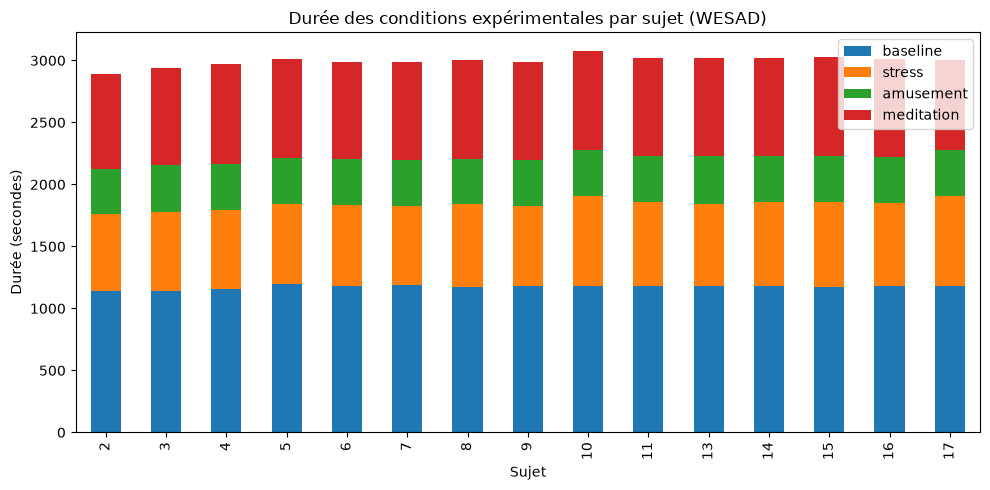

In [8]:
# --- Visualisation : durée de chaque condition par sujet ---
cond_cols = [c for c in ["baseline", "stress", "amusement", "meditation"] if c in subjects_df.columns]
ax = subjects_df[cond_cols].plot(kind="bar", stacked=True, figsize=(10, 5))
ax.set_ylabel("Durée (secondes)")
ax.set_xlabel("Sujet")
ax.set_title("Durée des conditions expérimentales par sujet (WESAD)")
plt.tight_layout()
plt.savefig("fig_conditions_par_sujet.png", dpi=120)
plt.show()


### 1.1 Exploration descriptive — synthèse (5 points)

Les tableaux et la figure ci-dessus montrent que :
- Le jeu de données contient des enregistrements **multi-sujets** et **multimodaux** : signaux physiologiques (ECG, EDA,
  EMG, température, respiration) et signal de mouvement (accélération), captés à deux endroits (poitrine et poignet).
- Les **fréquences d'échantillonnage diffèrent fortement** selon la modalité : 700 Hz à la poitrine contre 4 à 64 Hz au
  poignet. Cela signifie qu'on ne peut pas simplement concaténer les colonnes brutes : il faut agréger sur des fenêtres
  temporelles communes (fait en Question 2).
- Les **conditions expérimentales (baseline, stress, amusement, méditation)** ne durent pas exactement le même temps
  selon le sujet, et une partie non négligeable des enregistrements correspond à des **périodes de transition** (code 0),
  qui doivent être exclues ou traitées séparément pour ne pas polluer les analyses.
- L'**ordre temporel** est respecté dans le fichier : les échantillons sont dans l'ordre chronologique du protocole
  (baseline → tests de stress → amusement → récupération, selon le sujet), ce qui est essentiel pour la suite car
  toute notre analyse (prédictive et causale) dépend de cet ordre.

### 1.2 Algorithmes utilisables et justification (5 points)

Pour ce projet, je retiens un algorithme de chaque famille demandée, en priorisant à chaque fois l'algorithme le
plus efficace pour des données temporelles/tabulaires de taille modérée :

- **Apprentissage machine classique — Régression logistique et Gradient boosting (XGBoost).**
  Une fois les signaux transformés en variables agrégées par fenêtre (moyenne, écart-type, etc., voir Question 2), le
  problème devient un problème de classification tabulaire standard. La régression logistique sert de modèle de
  référence simple et interprétable. XGBoost construit ses arbres de façon séquentielle, chaque nouvel arbre
  corrigeant les erreurs des précédents, ce qui lui permet de bien exploiter des variables dérivées corrélées entre
  elles (ex. moyenne et écart-type d'un même signal) et d'obtenir une performance élevée sur ce type de données
  tabulaires — c'est l'un des résultats les plus reproductibles en apprentissage tabulaire (Grinsztajn et al., 2022).

- **Apprentissage profond — Réseau convolutionnel temporel (TCN, Temporal Convolutional Network).**
  Un TCN (Bai, Kolter & Koltun, 2018) empile des blocs de convolutions **causales et dilatées**, dont le facteur de
  dilatation double à chaque niveau (1, 2, 4, ...). Le champ récepteur de chaque neurone de sortie croît ainsi
  **exponentiellement** avec la profondeur du réseau, ce qui permet de capturer des dépendances temporelles
  **longues** (par exemple une dérive lente de l'activité électrodermale sur toute la fenêtre) avec un budget de
  paramètres raisonnable, sans le coût de calcul séquentiel ni les problèmes de gradient d'un LSTM/GRU, et avec un
  entraînement parallélisable stable sur un jeu de données de taille modérée comme WESAD (15 sujets). C'est un choix
  efficace en pratique pour la classification de séries temporelles physiologiques de longueur modérée.

  **Complément (retour prof) — un algorithme temporel classique :** l'évaluation honnête du TCN (Q3.3, split par
  sujet) montre qu'il sur-apprend fortement avec seulement ~9 sujets d'entraînement. En complément du TCN (qui
  reste le modèle *deep learning* demandé), on ajoute donc **ROCKET** (Dempster et al., 2020) : des noyaux de
  convolution **aléatoires et fixes** (non appris) appliqués à la séquence brute, suivis d'un classifieur
  linéaire. C'est un algorithme nativement conçu pour les séries temporelles, mais **classique** (aucun poids
  appris par rétropropagation) — donc beaucoup moins sujet au sur-apprentissage sur un petit nombre de sujets
  (détails en Question 3.3).

- **Méthode causale — Forêt causale (Causal Forest / arbre causal, via une approche de type double apprentissage
  machine).** Contrairement aux familles précédentes qui cherchent à **prédire** un état ou une sortie, la forêt
  causale cherche à estimer l'**effet** d'un traitement (être en condition stress) sur une sortie physiologique
  future, en ajustant sur des covariables observées, et surtout à estimer si cet effet est **hétérogène** selon les
  sujets. Les modèles de nuisance de la forêt causale (Question 5.2) sont eux-mêmes des modèles de **gradient
  boosting (XGBoost)**, car ils capturent bien des relations non linéaires entre covariables et traitement/sortie
  avec peu de variance — un ajustement de bonne qualité au premier stage du double machine learning réduit le biais
  de l'effet causal estimé au second stage. C'est l'outil adapté à la question causale de la Question 4, alors
  qu'aucun des deux modèles précédents ne répond à cette question même s'ils prédisent bien.


---
## Question 2 — Prétraitement temporel et création des variables dérivées (15 points)

### 2.0 Stratégie de synchronisation / agrégation (annoncée avant l'analyse)

Comme expliqué en Question 1, la poitrine (700 Hz) et le poignet (4 à 64 Hz) n'ont pas la même fréquence.
Le fichier `SX.pkl` fournit déjà les deux flux **synchronisés dans le temps** (même instant de départ, grâce au
tapotement double mentionné dans le fichier `readme` du dataset), mais **pas à la même fréquence**.

**Stratégie retenue :** je découpe l'enregistrement en fenêtres non chevauchantes de **10 secondes**, et pour
chaque fenêtre je calcule des statistiques agrégées (moyenne, écart-type, min, max, pente) séparément pour
chaque modalité, qu'elle vienne de la poitrine ou du poignet. Comme l'agrégation ramène tout à *une valeur par
fenêtre et par modalité*, la différence de fréquence d'origine ne pose plus de problème : une fenêtre de 10 s
contient 7000 échantillons ECG mais seulement 40 échantillons EDA au poignet, et les deux donnent une seule
moyenne pour cette fenêtre. C'est la solution la plus robuste pour combiner des signaux à fréquences très
différentes sans réinterpolation risquée.

Une fenêtre est étiquetée avec le label majoritaire (le label le plus fréquent parmi les échantillons à 700 Hz
contenus dans la fenêtre). Les fenêtres dont le label majoritaire est 0 (transition) ou 5/6/7 (à ignorer selon
le readme officiel du dataset) sont exclues, conformément aux instructions du dataset.

**pureté des fenêtres :** accepter une fenêtre dès que son label majoritaire est
valide ne suffit pas : une fenêtre pourrait être composée à 51% de `stress` et 49% de `baseline` (juste après
une transition) et serait quand même étiquetée `stress` en bloc, ce qui bruite les statistiques calculées sur
toute la fenêtre. On calcule donc désormais une **pureté** (proportion du label majoritaire dans la fenêtre) et
on exclut en plus les fenêtres dont la pureté est inférieure à `PURITY_THRESHOLD` (90%), pas seulement celles
dont le label majoritaire est invalide.


In [9]:
WINDOW_SECONDS = 10
WINDOW_SIZE_CHEST = WINDOW_SECONDS * FREQ_CHEST  # nb d'echantillons chest par fenetre = 7000

VALID_LABELS = {1, 2, 3}  # baseline, stress, amusement -> on ignore transition(0), meditation(4) et 5/6/7
# (on pourrait garder 4=meditation, mais le bareme et la question causale se concentrent sur stress vs le reste ;
#  on l'exclut ici pour garder une tache binaire/a 3 classes propre. Ce choix est annonce avant l'analyse.)

# Correction (retour prof) : une fenetre n'est gardee que si son label majoritaire couvre au moins
# cette proportion de la fenetre -> evite de garder des fenetres "mixtes" (plusieurs conditions
# mais acceptees car un label depasse tout juste les autres).
PURITY_THRESHOLD = 0.9

def slope(x):
    '''Pente simple (regression lineaire) d'un signal 1D sur son propre indice temporel.'''
    if len(x) < 2:
        return 0.0
    t = np.arange(len(x))
    return np.polyfit(t, x, 1)[0]

def acc_norm(acc_xyz):
    '''Norme du vecteur acceleration 3 axes, echantillon par echantillon.'''
    return np.linalg.norm(acc_xyz, axis=1)

# --- Explication des fonctions mathematiques utilisees ci-dessus ---
# slope(x) : pente d'une droite ajustee par moindres carres (np.polyfit(t, x, 1) resout
#   min sur (a,b) de la somme des (x - (a*t+b))^2 ; on garde seulement le coefficient
#   directeur a). Une pente positive/negative indique si le signal monte/descend sur la fenetre.
# acc_norm(acc_xyz) : norme euclidienne du vecteur acceleration 3 axes, calculee
#   echantillon par echantillon -> sqrt(x^2 + y^2 + z^2), independante de l'orientation du capteur.


In [10]:
def build_windows_for_subject(sid, data, window_seconds=WINDOW_SECONDS):
    '''Decoupe l'enregistrement d'un sujet en fenetres non chevauchantes et calcule les
    statistiques agregees par fenetre pour les modalites de la poitrine (base commune a 700Hz).
    Retourne un DataFrame avec une ligne par fenetre.
    '''
    chest = data["signal"]["chest"]
    label = data["label"].flatten()
    n_total = label.shape[0]
    win_size = window_seconds * FREQ_CHEST

    ecg = chest["ECG"].flatten()
    eda = chest["EDA"].flatten()
    emg = chest["EMG"].flatten()
    temp = chest["Temp"].flatten()
    resp = chest["Resp"].flatten()
    acc = chest["ACC"]  # (n,3)
    acc_n = acc_norm(acc)

    rows = []
    n_windows = n_total // win_size
    for w in range(n_windows):
        s, e = w * win_size, (w + 1) * win_size
        lab_window = label[s:e]
        # label majoritaire de la fenetre
        vals, counts = np.unique(lab_window, return_counts=True)
        majority_label = int(vals[np.argmax(counts)])
        purity = counts.max() / lab_window.shape[0]  # proportion du label majoritaire dans la fenetre
        if majority_label not in VALID_LABELS:
            continue  # on exclut transition / meditation / codes a ignorer
        if purity < PURITY_THRESHOLD:
            continue  # correction (retour prof) : fenetre trop "mixte" (plusieurs conditions) -> exclue

        row = {
            "subject": sid,
            "window_id": w,
            "t_start_s": s / FREQ_CHEST,           # index temporel explicite (debut de fenetre, en secondes)
            "t_since_start_s": s / FREQ_CHEST,      # temps ecoule depuis le debut du protocole (variable d'ajustement Q4)
            "label": majority_label,
            "condition": LABEL_MAP[majority_label],
            "purity": purity,
            "ecg_mean": ecg[s:e].mean(), "ecg_std": ecg[s:e].std(),
            "eda_mean": eda[s:e].mean(), "eda_std": eda[s:e].std(),
            "eda_slope": slope(eda[s:e]),
            "eda_min": eda[s:e].min(), "eda_max": eda[s:e].max(),
            "emg_mean": emg[s:e].mean(), "emg_std": emg[s:e].std(),
            "temp_mean": temp[s:e].mean(), "temp_std": temp[s:e].std(),
            "resp_mean": resp[s:e].mean(), "resp_std": resp[s:e].std(),
            "acc_norm_mean": acc_n[s:e].mean(), "acc_norm_std": acc_n[s:e].std(),
        }
        rows.append(row)

    return pd.DataFrame(rows)

# --- Explication des fonctions mathematiques utilisees ci-dessus ---
# .mean() : moyenne arithmetique = somme des valeurs divisee par leur nombre (tendance centrale).
# .std()  : ecart-type = racine carree de la moyenne des carres des ecarts a la moyenne
#   (mesure la dispersion du signal autour de sa moyenne).


### 2.1 Index temporel et respect de l'ordre chronologique (4 points)

Chaque fenêtre reçoit un `window_id` croissant et une colonne `t_start_s` / `t_since_start_s` qui donnent
la position exacte de la fenêtre dans le temps, **par sujet**. Ces colonnes jouent le rôle de l'index
temporel `t` demandé : elles permettent de trier les données dans l'ordre chronologique (indispensable pour
la séparation entraînement/test de la Question 3) et de mesurer le temps écoulé depuis le début du protocole
(variable d'ajustement essentielle pour la Question 4, car le stress n'est jamais assigné aléatoirement dans
le temps).


In [11]:
# --- Construction des fenetres pour tous les sujets charges en Question 1 ---
all_windows = []
for sid, d in raw_data.items():
    wdf = build_windows_for_subject(sid, d)
    all_windows.append(wdf)

windows_df = pd.concat(all_windows, ignore_index=True)
windows_df = windows_df.sort_values(["subject", "window_id"]).reset_index(drop=True)
print("Nombre total de fenetres (tous sujets, apres filtrage label + purete) :", len(windows_df))
print(f"Purete moyenne des fenetres conservees : {windows_df['purity'].mean():.3f} "
      f"(seuil impose : {PURITY_THRESHOLD})")
windows_df.head()


Nombre total de fenetres (tous sujets, apres filtrage label + purete) : 3275
Purete moyenne des fenetres conservees : 1.000 (seuil impose : 0.9)


,subject,window_id,t_start_s,t_since_start_s,label,condition,purity,ecg_mean,ecg_std,eda_mean,...,eda_min,eda_max,emg_mean,emg_std,temp_mean,temp_std,resp_mean,resp_std,acc_norm_mean,acc_norm_std
0,2,31,310.0,310.0,1,baseline,1.0,0.001121,0.134161,5.235050,...,5.109787,5.431366,-0.002653,0.017693,29.168968,0.033228,-0.120292,3.259859,0.929795,0.005274
1,2,32,320.0,320.0,1,baseline,1.0,0.000129,0.126072,5.105822,...,4.994202,5.209732,-0.002552,0.015100,29.164124,0.035072,0.252565,3.079841,0.933188,0.008428
2,2,33,330.0,330.0,1,baseline,1.0,0.004506,0.142350,4.898637,...,4.751968,5.094528,-0.002490,0.016677,29.238068,0.033676,0.046100,3.613581,0.934028,0.020994
3,2,34,340.0,340.0,1,baseline,1.0,-0.002003,0.148261,4.786782,...,4.729080,4.873276,-0.002740,0.010433,29.204103,0.054710,0.027374,2.809328,0.949158,0.047818
4,2,35,350.0,350.0,1,baseline,1.0,0.002450,0.141906,4.675575,...,4.555511,4.801559,-0.002736,0.009138,29.103380,0.048010,0.045715,1.746517,0.953591,0.004950


In [12]:
# --- Tableau recapitulatif des variables derivees creees (Q2), toutes fenetres/sujets confondus ---
recap_cols = ["ecg_mean", "ecg_std", "eda_mean", "eda_std", "eda_slope", "eda_min", "eda_max",
              "emg_mean", "emg_std", "temp_mean", "temp_std", "resp_mean", "resp_std",
              "acc_norm_mean", "acc_norm_std"]
recap_table = windows_df[recap_cols].describe().T[["mean", "std", "min", "max", "count"]].copy()
recap_table["count"] = recap_table["count"].astype(int)
for stat_col in ["mean", "std", "min", "max"]:
    # notation scientifique uniforme sur ces 4 colonnes (les variables couvrent des echelles tres
    # differentes, de ~1e-7 pour eda_slope a ~30 pour temp_mean : un affichage decimal fixe
    # ferait disparaitre les petites valeurs, d'ou ce choix coherent sur tout le tableau)
    recap_table[stat_col] = recap_table[stat_col].map(lambda v: f"{v:.4e}")
recap_table

,mean,std,min,max,count
ecg_mean,1.1013e-03,2.0700e-03,-1.4541e-02,1.6825e-02,3275
ecg_std,2.6291e-01,6.5276e-02,1.0206e-01,4.8247e-01,3275
eda_mean,4.6018e+00,3.4506e+00,5.6034e-01,2.0250e+01,3275
eda_std,2.4690e-02,4.2173e-02,5.6171e-03,8.4473e-01,3275
eda_slope,2.9531e-07,1.6078e-05,-2.9640e-04,3.4499e-04,3275
eda_min,4.4843e+00,3.4399e+00,0.0000e+00,2.0067e+01,3275
eda_max,4.7221e+00,3.4717e+00,6.5346e-01,2.0433e+01,3275
emg_mean,-2.9604e-03,9.5590e-04,-2.0980e-02,2.4886e-03,3275
emg_std,1.2794e-02,6.2849e-03,6.6496e-03,1.6316e-01,3275
temp_mean,3.3770e+01,1.3194e+00,2.8174e+01,3.5638e+01,3275


### 2.2 Nettoyage et standardisation (4 points)

**Valeurs manquantes :** dans les fichiers `.pkl` officiels, les signaux de la poitrine ne contiennent
normalement pas de trous (échantillonnage matériel continu à 700 Hz). On vérifie néanmoins systématiquement
ci-dessous, car un projet reproductible ne doit jamais supposer silencieusement que les données sont propres.

**Standardisation :** on standardise les variables physiologiques (moyenne 0, écart-type 1) **après** la
séparation entraînement/test et **en utilisant uniquement les paramètres appris sur l'entraînement**, pour
éviter toute fuite d'information du test vers l'entraînement (voir Question 3). Ici, en Question 2, on se
contente de vérifier l'absence de valeurs manquantes/aberrantes ; la standardisation elle-même est reportée
au pipeline de modélisation.


In [13]:
# --- Verification des valeurs manquantes ---
print("Valeurs manquantes par colonne :")
print(windows_df.isna().sum()[windows_df.isna().sum() > 0] if windows_df.isna().sum().sum() > 0
      else "Aucune valeur manquante detectee.")

# --- Verification de valeurs aberrantes grossieres (ex. temperature hors plage physiologique) ---
suspect = windows_df[(windows_df["temp_mean"] < 20) | (windows_df["temp_mean"] > 42)]
print(f"Fenetres avec temperature suspecte (hors 20-42C) : {len(suspect)}")

# On retire les eventuelles lignes suspectes (aucune attendue avec des donnees officielles propres)
windows_df = windows_df.drop(index=suspect.index).reset_index(drop=True)


Valeurs manquantes par colonne :
Aucune valeur manquante detectee.
Fenetres avec temperature suspecte (hors 20-42C) : 0


### 2.3 Variables dérivées (4 points)

Les variables dérivées créées par fenêtre de 10 secondes sont (au minimum les deux demandées, ici davantage
pour couvrir plusieurs modalités) :
- `eda_mean`, `eda_std`, `eda_slope`, `eda_min`, `eda_max` — activité électrodermale (marqueur classique du stress) ;
- `ecg_mean`, `ecg_std` — activité cardiaque brute (proxy de fréquence cardiaque avant extraction de pics R) ;
- `emg_mean`, `emg_std` — tension musculaire ;
- `temp_mean`, `temp_std` — température périphérique ;
- `resp_mean`, `resp_std` — respiration ;
- `acc_norm_mean`, `acc_norm_std` — norme du mouvement (variable de confusion importante : bouger davantage
  peut affecter la physiologie indépendamment du stress).


### 2.4 Sortie décalée dans le temps (3 points)

Pour préparer la question causale (Question 4), on ne veut pas seulement décrire l'état physiologique
**pendant** la fenêtre de stress, mais son effet sur l'état physiologique de la fenêtre **suivante**. On crée
donc, pour chaque sujet, une version décalée d'une fenêtre vers l'avant des variables cibles.

**Point de vigilance (retour prof) :** les fenêtres de transition ont déjà été retirées à la construction
(Question 2.0), donc `window_id` peut avoir des trous pour un même sujet (ex. `..., 31, 33, ...`). Un simple
décalage `shift(-1)` sur les lignes du DataFrame associerait alors, sans le vérifier, deux fenêtres qui ne sont
pas réellement adjacentes dans le temps. On vérifie donc explicitement `window_id_next == window_id + 1` avant
de considérer une paire de fenêtres comme "consécutive".


In [14]:
# --- Creation des sorties decalees (Y dans la fenetre suivante), par sujet ---
windows_df = windows_df.sort_values(["subject", "window_id"]).reset_index(drop=True)

# Correction (retour prof) : les fenetres de transition/meditation/purete insuffisante sont deja
# exclues de windows_df (Q2.0), donc deux lignes consecutives dans le DataFrame ne correspondent
# pas forcement a des fenetres temporellement adjacentes (window_id peut sauter). Un shift(-1)
# sans verification associerait alors des fenetres separees de plusieurs minutes. On verifie donc
# explicitement que window_id_next == window_id + 1 avant de garder le decalage.
windows_df["window_id_next"] = windows_df.groupby("subject")["window_id"].shift(-1)
is_contiguous_next = windows_df["window_id_next"] == windows_df["window_id"] + 1

shift_cols = ["eda_mean", "ecg_mean", "temp_mean", "resp_std"]
for col in shift_cols:
    shifted = windows_df.groupby("subject")[col].shift(-1)
    windows_df[f"{col}_next"] = shifted.where(is_contiguous_next)  # NaN si fenetre suivante non adjacente

n_gap = int((~is_contiguous_next).sum())
print(f"Fenetres sans fenetre suivante directement adjacente (fin de sujet ou trou) : {n_gap}")

# La derniere fenetre de chaque sujet (ou une fenetre suivie d'un trou) n'a pas de "fenetre
# suivante" valide -> on la retire pour les analyses qui utilisent la sortie decalee (elle reste
# utilisable pour la classification de la Question 3).
windows_df_with_next = windows_df.dropna(subset=[f"{c}_next" for c in shift_cols]).reset_index(drop=True)

print("Fenetres totales                :", len(windows_df))
print("Fenetres avec sortie decalee Y   :", len(windows_df_with_next))
windows_df_with_next[["subject", "window_id", "window_id_next", "condition", "eda_mean", "eda_mean_next"]].head(8)


Fenetres sans fenetre suivante directement adjacente (fin de sujet ou trou) : 45
Fenetres totales                : 3275
Fenetres avec sortie decalee Y   : 3230


,subject,window_id,window_id_next,condition,eda_mean,eda_mean_next
0,2,31,32.0,baseline,5.235050,5.105822
1,2,32,33.0,baseline,5.105822,4.898637
2,2,33,34.0,baseline,4.898637,4.786782
3,2,34,35.0,baseline,4.786782,4.675575
4,2,35,36.0,baseline,4.675575,4.529211
5,2,36,37.0,baseline,4.529211,4.386204
6,2,37,38.0,baseline,4.386204,4.249826
7,2,38,39.0,baseline,4.249826,4.105148


In [15]:
# --- Sauvegarde intermediaire pour reutilisation dans les questions suivantes ---
windows_df.to_csv("wesad_windows_10s.csv", index=False)
print("Fichier 'wesad_windows_10s.csv' sauvegarde :", windows_df.shape)


Fichier 'wesad_windows_10s.csv' sauvegarde : (3275, 27)


---
## Question 3 — Modèles prédictifs et apprentissage profond (20 points)

### 3.0 Formulation de la tâche prédictive (5 points)

**Tâche retenue :** classification **à 3 classes** de la condition physiologique de la fenêtre courante
(`baseline`, `stress`, `amusement`), à partir des variables de cette même fenêtre. Cette tâche est purement
**prédictive/descriptive** : elle répond à "peut-on reconnaître l'état du sujet à partir de ses signaux
physiologiques ?", ce qui est différent de la question causale de la Question 4 ("le stress cause-t-il un
changement physiologique dans la fenêtre suivante ?").

### 3.1 Séparation entraînement/validation/test — par sujet (avant les modèles)

**Correction (retour prof) :** la version précédente séparait chronologiquement **à l'intérieur de chaque
sujet** (70% des premières fenêtres au train, 30% des dernières au test). Cela évite bien la fuite temporelle
(des fenêtres quasi identiques à quelques secondes d'écart des deux côtés du split), mais un **même sujet**
se retrouvait quand même à la fois dans le train et dans le test : le modèle pouvait donc en partie apprendre
la "signature" physiologique individuelle de ce sujet plutôt que le phénomène de stress en général — une vraie
fuite d'information, pas seulement une limite mineure. De plus, comme la condition `baseline` est toujours
enregistrée en tout début de session, les 30% de fenêtres les plus tardives (le test) ne contenaient **aucune**
fenêtre baseline : l'évaluation à 3 classes n'était donc pas représentative.

**Nouvelle méthode :** on répartit des **sujets entiers**, sans chevauchement, en trois groupes :
- **entraînement** (~9 sujets) et **validation** (~3 sujets) : la validation sert uniquement à surveiller le
  TCN pendant l'entraînement (Question 3.3) sans jamais regarder le test ;
- **test** (~3 sujets), jamais vu pendant l'entraînement, évalué une seule fois.

Comme un sujet entier (avec toutes ses conditions, y compris son baseline) est assigné à un seul groupe, il
n'y a plus de fuite entre sujets, et le test contient bien les 3 conditions. C'est l'équivalent d'un pli d'un
`GroupKFold`/leave-one-subject-out (groupes = sujets) plutôt qu'un split aléatoire ou chronologique naïf.

**Pourquoi pas un mélange aléatoire fenêtre par fenêtre :** des fenêtres consécutives sont fortement corrélées
(le signal physiologique évolue lentement, l'état émotionnel dure plusieurs minutes). Mélanger aléatoirement
au niveau des fenêtres — même en respectant les sujets — rapprocherait des fenêtres presque identiques de part
et d'autre du split. On garde donc l'ordre temporel intact à l'intérieur de chaque sujet ; c'est la séparation
**par sujet** qui change, pas l'intégrité temporelle de chaque enregistrement.

**Vérification de robustesse :** en Question 3.2, on complète ce split fixe par une validation croisée
`GroupKFold` (groupes = sujets) sur les modèles classiques, pour vérifier que la performance ne dépend pas
d'un choix particulier de 3 sujets de test.


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report)
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Tri chronologique global (utile pour les features de lag / sequences plus loin)
windows_df = windows_df.sort_values(["subject", "window_id"]).reset_index(drop=True)

# --- Split PAR SUJET (correction retour prof, Q1/Q3.1) ---
# L'ancien split coupait CHAQUE sujet en un morceau train et un morceau test (70/30 dans l'ordre
# du temps) : le meme sujet apparaissait donc des deux cotes -> fuite entre sujets. De plus,
# baseline etant toujours en debut de session, le test (fenetres les plus tardives) ne contenait
# jamais de fenetre baseline -> evaluation a 3 classes non representative (ancien constat de Q3.4).
# Desormais, des SUJETS ENTIERS sont repartis en train / validation / test SANS chevauchement :
# chaque sujet n'apparait que dans un seul sous-ensemble.
TEST_FRAC_SUBJECTS = 0.2   # ~3 sujets sur 15, jamais vus pendant l'entrainement
VAL_FRAC_SUBJECTS = 0.2    # ~3 sujets sur 15, reserves a la surveillance du TCN (Q3.3)

rng = np.random.RandomState(RANDOM_STATE)
subjects_shuffled = rng.permutation(SUBJECTS)
n_subj = len(subjects_shuffled)
n_test = max(1, round(n_subj * TEST_FRAC_SUBJECTS))
n_val = max(1, round(n_subj * VAL_FRAC_SUBJECTS))

test_subjects = sorted(subjects_shuffled[:n_test].tolist())
val_subjects = sorted(subjects_shuffled[n_test:n_test + n_val].tolist())
train_subjects = sorted(subjects_shuffled[n_test + n_val:].tolist())

assert not (set(train_subjects) & set(val_subjects)), "un sujet est a la fois en train et en validation"
assert not (set(train_subjects) & set(test_subjects)), "un sujet est a la fois en train et en test"
assert not (set(val_subjects) & set(test_subjects)), "un sujet est a la fois en validation et en test"

print("Sujets entrainement :", train_subjects)
print("Sujets validation   :", val_subjects, " (reserves a la surveillance du TCN, Q3.3)")
print("Sujets test         :", test_subjects, " (jamais vus pendant l'entrainement, evalues une seule fois)")

train_df = windows_df[windows_df["subject"].isin(train_subjects)].reset_index(drop=True)
val_df = windows_df[windows_df["subject"].isin(val_subjects)].reset_index(drop=True)
test_df = windows_df[windows_df["subject"].isin(test_subjects)].reset_index(drop=True)

# Les modeles ML classiques (regression logistique, XGBoost) ne sont pas entraines de facon
# iterative avec surveillance d'une perte de validation (contrairement au TCN, Q3.3) : ils
# utilisent donc train+val comme entrainement, et test comme seule evaluation.
train_clf_df = pd.concat([train_df, val_df], ignore_index=True)

print(f"\nFenetres ML classique -> entrainement (train+val) : {len(train_clf_df)}  |  test : {len(test_df)}")
print(f"Fenetres TCN -> entrainement : {len(train_df)}  |  validation : {len(val_df)}  |  test : {len(test_df)}")

# Repartition des classes : le test contient maintenant les 3 conditions (l'ancien probleme de la
# Q3.4 -- test sans aucune fenetre baseline -- ne se reproduit plus, car un sujet entier, avec
# toutes ses conditions, est desormais reserve au test)
repartition_df = pd.DataFrame({
    "train (ML classique)": train_clf_df["condition"].value_counts(normalize=True).round(3),
    "test": test_df["condition"].value_counts(normalize=True).round(3),
}).fillna(0)
repartition_df.index.name = "condition"
display(repartition_df)


Sujets entrainement : [3, 4, 5, 6, 8, 9, 13, 15, 17]
Sujets validation   : [7, 10, 16]  (reserves a la surveillance du TCN, Q3.3)
Sujets test         : [2, 11, 14]  (jamais vus pendant l'entrainement, evalues une seule fois)

Fenetres ML classique -> entrainement (train+val) : 2625  |  test : 650
Fenetres TCN -> entrainement : 1963  |  validation : 662  |  test : 650


,train (ML classique),test
condition,,
baseline,0.533,0.535
stress,0.300,0.298
amusement,0.166,0.166


In [17]:
# --- Variables explicatives : uniquement les statistiques de la fenetre COURANTE ---
# (on exclut explicitement les colonnes "_next" : elles sont reservees a la question causale
#  et ne doivent jamais servir a predire la condition de la fenetre courante -> fuite du futur)
feature_cols = ["ecg_mean", "ecg_std", "eda_mean", "eda_std", "eda_slope", "eda_min", "eda_max",
                 "emg_mean", "emg_std", "temp_mean", "temp_std", "resp_mean", "resp_std",
                 "acc_norm_mean", "acc_norm_std"]

X_train_raw = train_clf_df[feature_cols].values
X_test_raw = test_df[feature_cols].values
y_train = train_clf_df["condition"].values
y_test = test_df["condition"].values

# Standardisation : parametres appris UNIQUEMENT sur l'entrainement (evite la fuite test->train)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Shape X_train:", X_train.shape, " X_test:", X_test.shape)

# --- Explication de la fonction mathematique utilisee ci-dessus ---
# StandardScaler : standardisation (score z) de chaque variable ->
#   x_standardise = (x - moyenne) / ecart-type, moyenne et ecart-type appris uniquement sur
#   le train. Met toutes les variables a la meme echelle (moyenne 0, ecart-type 1).


Shape X_train: (2625, 15)  X_test: (650, 15)


### 3.2 Modèles d'apprentissage machine classiques (5 points)

Deux modèles complémentaires : une **régression logistique** (linéaire, interprétable, sert de base de
comparaison) et un **gradient boosting (XGBoost)**, qui construit ses arbres séquentiellement en corrigeant
les erreurs des précédents, ce qui lui donne une bonne performance sur des variables tabulaires dérivées
comme les nôtres (voir justification en Question 1.2).


In [18]:
# --- Robustesse : validation croisee GroupKFold (correction retour prof, Q1/Q3.1) ---
# En plus du split fixe train/test par sujet ci-dessus, on verifie que la performance ne depend
# pas d'un choix particulier de 3 sujets de test : GroupKFold (groupes = sujets) garantit qu'un
# meme sujet n'est jamais a la fois dans le train et le test d'un pli, et on fait tourner
# l'evaluation sur PLUSIEURS repartitions differentes des 15 sujets (equivalent d'un
# leave-one-subject-out partiel). Le pipeline (scaler + modele) est refait a l'interieur de
# chaque pli pour ne pas fuiter les statistiques de standardisation d'un pli a l'autre.
X_all = windows_df[feature_cols].values
y_all = windows_df["condition"].values
groups_all = windows_df["subject"].values

# XGBoost (API sklearn) exige des labels entiers 0..K-1 : on encode une bonne fois pour la CV
# (accuracy/f1_macro ne dependent pas de la representation des labels, tant qu'elle est coherente).
y_all_enc = LabelEncoder().fit_transform(y_all)

group_kfold = GroupKFold(n_splits=5)
cv_pipelines = {
    "Regression logistique": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "XGBoost": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                               random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)),
    ]),
}
for name, estimator in cv_pipelines.items():
    cv_scores = cross_validate(estimator, X_all, y_all_enc, groups=groups_all, cv=group_kfold,
                                 scoring=["accuracy", "f1_macro"], n_jobs=-1)
    print(f"{name:25s} GroupKFold(5, par sujet) accuracy = {cv_scores['test_accuracy'].mean():.3f} "
          f"+/- {cv_scores['test_accuracy'].std():.3f}   "
          f"f1_macro = {cv_scores['test_f1_macro'].mean():.3f} +/- {cv_scores['test_f1_macro'].std():.3f}")

# --- Entrainement final sur train+val, evaluation sur le test tenu a part (sujets jamais vus) ---
# Regression logistique : modele lineaire de reference, peu de risque de surapprentissage
# vu le nombre modere de variables (15) et de fenetres.
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

# XGBoost attend des labels entiers 0..K-1 : on encode les conditions (baseline/stress/amusement)
class_encoder = LabelEncoder()
y_train_enc = class_encoder.fit_transform(y_train)
y_test_enc = class_encoder.transform(y_test)

# Hyperparametres choisis pour limiter le surapprentissage sur un jeu de taille moderee :
# - max_depth=4 : arbres peu profonds (15 variables seulement, pas besoin d'interactions tres complexes)
# - learning_rate=0.05 bas + n_estimators=300 eleve : apprentissage progressif, plus stable
#   qu'un taux d'apprentissage eleve avec peu d'arbres
# - subsample=0.8 / colsample_bytree=0.8 : chaque arbre ne voit que 80% des lignes/colonnes,
#   ce qui reduit la variance (un peu comme un bagging a l'interieur du boosting)
# - reg_lambda=1.0 : regularisation L2 standard sur le poids des feuilles
xgb_clf = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
    n_jobs=-1,
)
xgb_clf.fit(X_train, y_train_enc)
y_pred_xgb_enc = xgb_clf.predict(X_test)
y_pred_xgb = class_encoder.inverse_transform(y_pred_xgb_enc)  # retour aux labels textuels

def print_metrics(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")  # macro = moyenne non ponderee entre classes
                                                       # (utile car les classes sont desequilibrees)
    report_df = pd.DataFrame(
        classification_report(y_true, y_pred, zero_division=0, output_dict=True)
    ).transpose().round(3)

    print(f"--- {name} ---")
    print(f"Exactitude (accuracy) : {acc:.3f}")
    print(f"F1 macro               : {f1m:.3f}")
    display(report_df)

print_metrics("Regression logistique", y_test, y_pred_lr)
print_metrics("XGBoost (gradient boosting)", y_test, y_pred_xgb)

# --- Explication des fonctions mathematiques utilisees ci-dessus ---
# LogisticRegression : calcule un score lineaire (somme ponderee des variables) par classe,
#   puis applique la fonction softmax (exp(score_k) / somme des exp(score_j)) pour transformer
#   ces scores en probabilites qui somment a 1.
# XGBoost (gradient boosting) : construit des arbres de decision les uns apres les autres,
#   chaque nouvel arbre corrigeant l'erreur (le gradient de la perte) laissee par les precedents.
# f1_score : moyenne harmonique de la precision et du rappel ->
#   2 * (precision * rappel) / (precision + rappel) ; "macro" = moyenne non ponderee entre classes.


Regression logistique     GroupKFold(5, par sujet) accuracy = 0.636 +/- 0.118   f1_macro = 0.519 +/- 0.114


XGBoost                   GroupKFold(5, par sujet) accuracy = 0.676 +/- 0.060   f1_macro = 0.567 +/- 0.073


--- Regression logistique ---
Exactitude (accuracy) : 0.723
F1 macro               : 0.620


,precision,recall,f1-score,support
amusement,0.444,0.259,0.327,108.000
baseline,0.744,0.894,0.812,348.000
stress,0.775,0.675,0.722,194.000
accuracy,0.723,0.723,0.723,0.723
macro avg,0.655,0.609,0.620,650.000
weighted avg,0.704,0.723,0.705,650.000


--- XGBoost (gradient boosting) ---
Exactitude (accuracy) : 0.634
F1 macro               : 0.608


,precision,recall,f1-score,support
amusement,0.356,0.528,0.425,108.000
baseline,0.718,0.601,0.654,348.000
stress,0.734,0.753,0.743,194.000
accuracy,0.634,0.634,0.634,0.634
macro avg,0.603,0.627,0.608,650.000
weighted avg,0.663,0.634,0.643,650.000


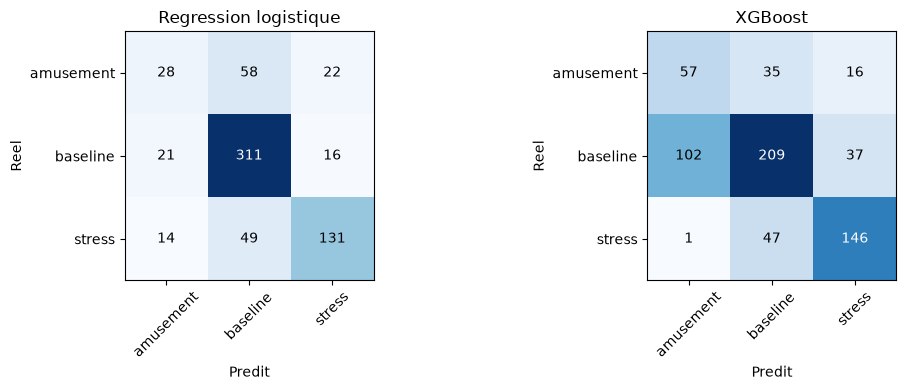

In [19]:
# --- Matrices de confusion ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, y_pred) in zip(axes, [("Regression logistique", y_pred_lr), ("XGBoost", y_pred_xgb)]):
    labels_order = sorted(windows_df["condition"].unique())
    cm = confusion_matrix(y_test, y_pred, labels=labels_order)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels_order))); ax.set_xticklabels(labels_order, rotation=45)
    ax.set_yticks(range(len(labels_order))); ax.set_yticklabels(labels_order)
    ax.set_xlabel("Predit"); ax.set_ylabel("Reel"); ax.set_title(name)
    for i in range(len(labels_order)):
        for j in range(len(labels_order)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout()
plt.savefig("fig_confusion_ml_classique.png", dpi=120)
plt.show()


### 3.3 Modèle d'apprentissage profond — TCN (réseau convolutionnel temporel) sur séquences de signal (5 points)

Contrairement aux deux modèles précédents qui utilisent des statistiques déjà résumées par fenêtre, le TCN
apprend directement sur la **séquence temporelle brute** de chaque fenêtre (les 8 canaux de la poitrine : ECG,
EDA, EMG, Temp, Resp, ACC x/y/z), afin d'extraire lui-même les motifs pertinents plutôt que de dépendre de
statistiques choisies manuellement.

**Pourquoi un TCN :** un TCN (Bai, Kolter & Koltun, 2018) empile des blocs de convolutions **causales et
dilatées**, dont le facteur de dilatation double à chaque couche (1, 2, 4, ...). Le champ récepteur de chaque
neurone de sortie croît ainsi **exponentiellement** avec la profondeur du réseau, ce qui permet de capturer
des dépendances temporelles longues (par exemple une dérive lente de l'activité électrodermale sur toute la
fenêtre) avec un budget de paramètres raisonnable, sans la lenteur d'entraînement séquentiel ni les problèmes
de gradient d'un réseau récurrent. Sur un jeu de données de taille modérée comme WESAD (15 sujets), cette
efficacité paramétrique et cette stabilité d'entraînement en font un choix performant en pratique.

**Choix technique :** une fenêtre de 10 s à 700 Hz contient 7000 points par canal, ce qui est inutilement lourd
et contient beaucoup de fréquences non pertinentes pour cette tâche (ex. le bruit haute fréquence de l'EMG).
On **sous-échantillonne à 100 Hz** (un point sur 7), ce qui ramène chaque fenêtre à une séquence de 1000 pas de
temps par canal — largement suffisant pour capturer la dynamique cardiaque, électrodermale et respiratoire
pertinente pour la détection de stress, tout en réduisant fortement le temps de calcul. **Correction (retour
prof) :** un simple `seq[::7]` sous-échantillonne sans filtre anti-repliement (les fréquences au-dessus de la
nouvelle fréquence de Nyquist, 50 Hz, se replient et polluent le signal décimé) — on applique désormais un
filtre passe-bas (via `scipy.signal.decimate`) avant de sous-échantillonner.

**Surveillance de l'entraînement (retour prof) :** le test était auparavant consulté à *chaque* époque pour
tracer la courbe de perte, ce qui en faisait implicitement un ensemble de validation — toute lecture de cette
courbe pour choisir le nombre d'époques aurait donc biaisé (de façon optimiste) l'évaluation finale. On utilise
désormais un ensemble de **validation** distinct (sujets Q3.1) pour cette surveillance ; le test n'est évalué
qu'une seule fois, après la fin de l'entraînement.


In [20]:
from scipy.signal import decimate

DOWNSAMPLE_FACTOR = 7  # 700 Hz -> 100 Hz
CHEST_CHANNELS = ["ECG", "EDA", "EMG", "Temp", "Resp"]  # + ACC x,y,z ajoutes separement (3 axes)

def build_sequence_for_window(sid, window_id, downsample=DOWNSAMPLE_FACTOR):
    '''Extrait la sequence brute (sous-echantillonnee) des 8 canaux de la poitrine pour une fenetre donnee.'''
    chest = raw_data[sid]["signal"]["chest"]
    s = window_id * WINDOW_SIZE_CHEST
    e = s + WINDOW_SIZE_CHEST
    channels = [chest[c][s:e, 0] for c in CHEST_CHANNELS]
    acc = chest["ACC"][s:e, :]  # (win_size, 3)
    channels += [acc[:, 0], acc[:, 1], acc[:, 2]]
    seq = np.stack(channels, axis=1)  # (win_size, 8)
    # Correction (retour prof) : un simple seq[::downsample] sous-echantillonne sans filtre
    # anti-repliement -> les frequences au-dessus de la nouvelle frequence de Nyquist (50 Hz)
    # se replient et polluent le signal decime. scipy.signal.decimate applique d'abord un
    # filtre passe-bas (Chebyshev, zero-phase) avant de sous-echantillonner.
    return decimate(seq, downsample, axis=0, zero_phase=True)  # (win_size/downsample, 8)

# Verification rapide sur une fenetre
_test_seq = build_sequence_for_window(train_df.iloc[0]["subject"], train_df.iloc[0]["window_id"])
print("Forme d'une sequence de fenetre :", _test_seq.shape, "(pas_de_temps, canaux)")


Forme d'une sequence de fenetre : (1000, 8) (pas_de_temps, canaux)


In [21]:
# --- Construction des tenseurs de sequences pour train/validation/test ---
# ATTENTION : selon la RAM disponible, ceci peut prendre 1-2 minutes mais reste largement gerable
# (environ 3300 fenetres x 1000 pas de temps x 8 canaux x 4 octets ~= 100 Mo au total).

def build_sequence_dataset(df):
    seqs = np.stack([build_sequence_for_window(row["subject"], row["window_id"])
                       for _, row in df.iterrows()], axis=0)
    return seqs  # (n_windows, seq_len, n_channels)

X_seq_train_raw = build_sequence_dataset(train_df)
X_seq_val_raw = build_sequence_dataset(val_df)
X_seq_test_raw = build_sequence_dataset(test_df)
print("X_seq_train:", X_seq_train_raw.shape, " X_seq_val:", X_seq_val_raw.shape,
      " X_seq_test:", X_seq_test_raw.shape)


X_seq_train: (1963, 1000, 8)  X_seq_val: (662, 1000, 8)  X_seq_test: (650, 1000, 8)


In [22]:
# --- Standardisation par canal, parametres appris UNIQUEMENT sur l'entrainement ---
seq_mean = X_seq_train_raw.mean(axis=(0, 1), keepdims=True)
seq_std = X_seq_train_raw.std(axis=(0, 1), keepdims=True) + 1e-8

X_seq_train = (X_seq_train_raw - seq_mean) / seq_std
X_seq_val = (X_seq_val_raw - seq_mean) / seq_std
X_seq_test = (X_seq_test_raw - seq_mean) / seq_std

# Encodage des labels (memes classes que pour les modeles ML classiques)
CLASSES = sorted(windows_df["condition"].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
y_train_idx = train_df["condition"].map(class_to_idx).values
y_val_idx = val_df["condition"].map(class_to_idx).values
y_test_idx = test_df["condition"].map(class_to_idx).values
print("Classes :", CLASSES)

# --- Explication de la fonction mathematique utilisee ci-dessus ---
# Standardisation (score z), ici canal par canal sur les sequences temporelles :
#   x_standardise = (x - moyenne_canal) / (ecart-type_canal + 1e-8), moyenne et ecart-type
#   appris uniquement sur le train (le +1e-8 evite une division par zero si un canal est constant).


Classes : ['amusement', 'baseline', 'stress']


In [23]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(RANDOM_STATE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilise :", device)

class TemporalBlock(nn.Module):
    '''Bloc de base d'un TCN : deux convolutions causales dilatees + connexion residuelle
    (Bai, Kolter & Koltun, 2018).'''
    def __init__(self, n_inputs, n_outputs, kernel_size, dilation, dropout=0.2):
        super().__init__()
        self.padding = (kernel_size - 1) * dilation
        self.conv1 = nn.Conv1d(n_inputs, n_outputs, kernel_size, padding=self.padding, dilation=dilation)
        self.conv2 = nn.Conv1d(n_outputs, n_outputs, kernel_size, padding=self.padding, dilation=dilation)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        # 1x1 conv si le nombre de canaux change, pour que la connexion residuelle (out + res)
        # reste possible dimensionnellement
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None

    def _causal(self, x, conv):
        # padding symetrique de conv1d -> on retire les pas de temps "futurs" en trop a droite,
        # pour que la sortie au temps t ne depende jamais d'entrees futures (t+1, t+2, ...)
        out = conv(x)
        return out[:, :, :-self.padding] if self.padding > 0 else out

    def forward(self, x):
        out = self.dropout(self.relu(self._causal(x, self.conv1)))
        out = self.dropout(self.relu(self._causal(out, self.conv2)))
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)

class TCN(nn.Module):
    '''Reseau convolutionnel temporel : pile de blocs a dilatation croissante (1, 2, 4, ...)
    suivie d'un average pooling global et d'une couche de classification.'''
    def __init__(self, n_channels, n_classes, num_channels=(32, 64, 64), kernel_size=5, dropout=0.2):
        super().__init__()
        layers = []
        in_ch = n_channels
        for i, out_ch in enumerate(num_channels):
            dilation = 2 ** i  # 1, 2, 4, ... -> champ receptif qui croit exponentiellement avec la profondeur
            layers.append(TemporalBlock(in_ch, out_ch, kernel_size, dilation, dropout))
            in_ch = out_ch
        self.tcn = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)  # moyenne sur tout l'axe temporel -> une longueur de sequence fixe en sortie
        self.fc = nn.Linear(num_channels[-1], n_classes)

    def forward(self, x):
        # x: (batch, seq_len, channels) -> (batch, channels, seq_len) pour Conv1d
        x = x.permute(0, 2, 1)
        z = self.tcn(x)
        z = self.pool(z).squeeze(-1)
        return self.fc(z)

# Choix d'architecture (valeurs usuelles du papier TCN original, Bai et al. 2018) :
# - num_channels=(32, 64, 64) : 3 blocs a dilatation croissante -> champ receptif suffisamment
#   large pour capturer un cycle cardiaque/respiratoire, sans trop de parametres pour 15 sujets
# - kernel_size=5, dropout=0.2 : compromis classique complexite/regularisation adapte a un
#   jeu de donnees de taille moderee
model = TCN(n_channels=X_seq_train.shape[2], n_classes=len(CLASSES)).to(device)
print(model)

# --- Explication des fonctions mathematiques utilisees ci-dessus ---
# Conv1d (convolution dilatee) : fait glisser un filtre de poids sur la sequence et calcule a
#   chaque position une somme ponderee locale des entrees ; la dilatation espace les points vus
#   par le filtre, ce qui elargit le champ receptif sans ajouter de parametres.
# ReLU(x) = max(0, x) : fonction d'activation non lineaire qui annule les valeurs negatives.
# Connexion residuelle (out + res) : additionne l'entree du bloc a sa sortie, ce qui facilite
#   l'entrainement de reseaux profonds en laissant le gradient circuler plus directement.
# AdaptiveAvgPool1d : moyenne les valeurs sur tout l'axe temporel pour obtenir une sortie de
#   taille fixe, quelle que soit la longueur de la sequence en entree.


Device utilise : cpu
TCN(
  (tcn): Sequential(
    (0): TemporalBlock(
      (conv1): Conv1d(8, 32, kernel_size=(5,), stride=(1,), padding=(4,))
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(4,))
      (relu): ReLU()
      (dropout): Dropout(p=0.2, inplace=False)
      (downsample): Conv1d(8, 32, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (conv1): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(8,), dilation=(2,))
      (conv2): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(8,), dilation=(2,))
      (relu): ReLU()
      (dropout): Dropout(p=0.2, inplace=False)
      (downsample): Conv1d(32, 64, kernel_size=(1,), stride=(1,))
    )
    (2): TemporalBlock(
      (conv1): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(16,), dilation=(4,))
      (conv2): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(16,), dilation=(4,))
      (relu): ReLU()
      (dropout): Dropout(p=0.2, inplace=False)
    )
  )
  (pool): Ada

In [24]:
# --- Preparation des DataLoaders ---
BATCH_SIZE = 32
train_ds = TensorDataset(torch.tensor(X_seq_train, dtype=torch.float32),
                           torch.tensor(y_train_idx, dtype=torch.long))
val_ds = TensorDataset(torch.tensor(X_seq_val, dtype=torch.float32),
                         torch.tensor(y_val_idx, dtype=torch.long))
test_ds = TensorDataset(torch.tensor(X_seq_test, dtype=torch.float32),
                          torch.tensor(y_test_idx, dtype=torch.long))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)  # jamais consulte pendant l'entrainement

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)  # taux d'apprentissage standard pour Adam
criterion = nn.CrossEntropyLoss()  # adaptee a la classification multi-classe (3 classes)

N_EPOCHS = 15
history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = None
best_epoch = -1

# Correction (retour prof) : le test etait auparavant consulte a CHAQUE epoque (test_loss
# calculee et affichee 15 fois), ce qui en faisait implicitement un ensemble de validation -> le
# regarder pour choisir le nombre d'epoques aurait biaise l'evaluation finale de facon optimiste.
# On surveille desormais un ensemble de VALIDATION distinct (sujets jamais vus par le train NI
# par le test, cf Q3.1) ; le test n'est evalue qu'une seule fois, apres l'entrainement (cellule
# suivante). Consequence directe et naturelle d'avoir un vrai jeu de validation : on l'utilise
# aussi pour de l'early stopping (on garde les poids de l'epoque de meilleure val_loss, pas
# forcement la derniere), plutot que de fixer arbitrairement N_EPOCHS et de garder le dernier etat.
for epoch in range(N_EPOCHS):
    model.train()  # active le dropout pendant l'entrainement
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()      # reinitialise les gradients (sinon ils s'accumuleraient d'un batch a l'autre)
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()            # retropropagation : calcule le gradient de la perte
        optimizer.step()           # met a jour les poids du modele avec ce gradient
        total_loss += loss.item() * xb.size(0)
    train_loss = total_loss / len(train_ds)

    model.eval()  # desactive le dropout pour l'evaluation (comportement deterministe)
    total_val_loss = 0.0
    with torch.no_grad():  # pas de calcul de gradient necessaire en evaluation -> plus rapide, moins de memoire
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total_val_loss += criterion(out, yb).item() * xb.size(0)
    val_loss = total_val_loss / len(val_ds)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoque {epoch+1:2d}/{N_EPOCHS}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

print(f"\nMeilleure epoque (min val_loss) : {best_epoch}/{N_EPOCHS}  (val_loss={best_val_loss:.4f})")
_ = model.load_state_dict(best_state)  # on repart avec les poids de la meilleure epoque, pas ceux de la derniere

# --- Explication des fonctions mathematiques utilisees ci-dessus ---
# CrossEntropyLoss : mesure l'ecart entre les probabilites predites et la vraie classe ->
#   -log(probabilite predite pour la vraie classe) ; plus cette probabilite est faible, plus la
#   perte est elevee.
# loss.backward() (retropropagation) : calcule, via la regle de derivation en chaine, le gradient
#   de la perte par rapport a chaque poids du reseau.
# Adam (optimizer.step()) : met a jour chaque poids dans le sens oppose a son gradient, en
#   adaptant le pas d'apprentissage a partir de moyennes mobiles du gradient et de son carre.


Epoque  1/15  train_loss=0.6560  val_loss=2.4251


Epoque  2/15  train_loss=0.4221  val_loss=4.7019


Epoque  3/15  train_loss=0.3248  val_loss=5.7892


Epoque  4/15  train_loss=0.2492  val_loss=9.0924


Epoque  5/15  train_loss=0.1623  val_loss=11.1624


...

Epoque 11/15  train_loss=0.0164  val_loss=18.0090


Epoque 12/15  train_loss=0.0344  val_loss=16.3926


Epoque 13/15  train_loss=0.0247  val_loss=16.6968


Epoque 14/15  train_loss=0.0127  val_loss=16.4233


Epoque 15/15  train_loss=0.0104  val_loss=15.3720

Meilleure epoque (min val_loss) : 1/15  (val_loss=2.4251)


--- TCN (deep learning, poids de l'epoque 1) ---
Exactitude (accuracy) : 0.478
F1 macro               : 0.335


,precision,recall,f1-score,support
amusement,0.067,0.009,0.016,108.000
baseline,0.581,0.661,0.618,348.000
stress,0.335,0.412,0.370,194.000
accuracy,0.478,0.478,0.478,0.478
macro avg,0.327,0.361,0.335,650.000
weighted avg,0.422,0.478,0.444,650.000


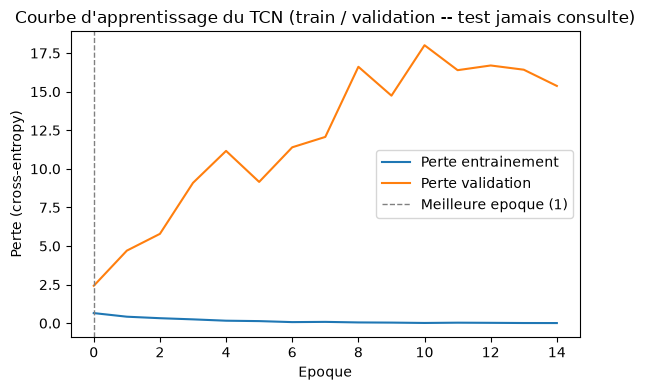

In [25]:
# --- Evaluation finale du TCN (UNE SEULE FOIS, apres la fin de l'entrainement) ---
# On evalue le modele de la MEILLEURE epoque (early stopping sur la validation, cellule
# precedente), pas necessairement celui de la derniere epoque.
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        out = model(xb)
        preds = out.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(yb.numpy())

y_pred_tcn = [CLASSES[i] for i in all_preds]
y_true_seq = [CLASSES[i] for i in all_true]

print_metrics(f"TCN (deep learning, poids de l'epoque {best_epoch})", y_true_seq, y_pred_tcn)

plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="Perte entrainement")
plt.plot(history["val_loss"], label="Perte validation")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", linewidth=1,
            label=f"Meilleure epoque ({best_epoch})")
plt.xlabel("Epoque"); plt.ylabel("Perte (cross-entropy)")
plt.title("Courbe d'apprentissage du TCN (train / validation -- test jamais consulte)")
plt.legend(); plt.tight_layout()
plt.savefig("fig_courbe_apprentissage_tcn.png", dpi=120)
plt.show()


### Complément — ROCKET : un modèle temporel classique (au-delà du barème)

Le TCN ci-dessus est le modèle *deep learning* demandé par la consigne (Q1.2/Q3), mais son évaluation honnête
(Q3.1-3.3) montre qu'il sur-apprend fortement avec seulement ~9 sujets d'entraînement. En complément — pas en
remplacement — on ajoute **ROCKET** (Dempster, Petitjean & Webb, 2020), un modèle **spécifiquement conçu pour
la classification de séries temporelles**, qui répond à la fois à l'exigence d'un algorithme *adapté aux
données temporelles* et à celle d'un algorithme *classique* (ce n'est **pas** du deep learning) :

- **Principe :** ROCKET applique un grand nombre (ici 10 000) de **noyaux de convolution aléatoires fixes**
  (longueur, poids, dilatation et biais tirés aléatoirement, jamais appris) directement sur la séquence brute
  de chaque fenêtre, puis calcule 2 statistiques simples par noyau (le maximum, et la proportion de valeurs
  positives). On obtient ainsi 20 000 variables par fenêtre, sur lesquelles on entraîne un **classifieur
  linéaire** (`RidgeClassifierCV`, avec sélection automatique de la régularisation par validation croisée).
- **Pourquoi c'est temporel :** contrairement à la régression logistique/XGBoost (Q3.2), qui reçoivent des
  statistiques déjà résumées par fenêtre (moyenne, écart-type...), ROCKET reçoit la **séquence brute** — les
  motifs temporels (forme d'onde, transitoires) sont détectés directement par les noyaux convolutionnels.
- **Pourquoi c'est plus robuste que le TCN ici :** les noyaux ne sont **pas appris** (donc pas de risque de
  sur-apprentissage sur leurs poids), seul le classifieur linéaire final est entraîné — beaucoup moins de
  paramètres à estimer que le TCN avec seulement ~9 sujets. C'est un choix bien documenté dans la littérature
  pour la classification de séries temporelles sur des jeux de données de taille modérée, y compris
  spécifiquement sur WESAD (évaluation leave-one-subject-out).
- Comme pour les modèles classiques (Q3.2), on entraîne sur train+validation (`train_clf_df`) et on évalue
  une seule fois sur le test (mêmes sujets de test que tous les autres modèles, pour une comparaison honnête).


In [26]:
from sktime.transformations.panel.rocket import Rocket
from sklearn.linear_model import RidgeClassifierCV

# ROCKET attend un tableau (n_instances, n_canaux, n_pas_de_temps) -> on transpose nos sequences
# (n_instances, n_pas_de_temps, n_canaux) construites en Q3.3 (mêmes sequences brutes que le TCN,
# AVANT la standardisation par canal : ROCKET normalise chaque serie lui-meme, normalise=True).
X_seq_train_clf_raw = np.concatenate([X_seq_train_raw, X_seq_val_raw], axis=0)  # train+val, comme Q3.2
y_train_clf_idx = np.concatenate([y_train_idx, y_val_idx], axis=0)

X_rocket_train_in = X_seq_train_clf_raw.transpose(0, 2, 1)  # (n, canaux, temps)
X_rocket_test_in = X_seq_test_raw.transpose(0, 2, 1)

rocket = Rocket(num_kernels=10000, normalise=True, n_jobs=-1, random_state=RANDOM_STATE)
rocket.fit(X_rocket_train_in)
X_rocket_train = rocket.transform(X_rocket_train_in)
X_rocket_test = rocket.transform(X_rocket_test_in)
print("Features ROCKET :", X_rocket_train.shape, "(", X_rocket_train.shape[1] // 2, "noyaux x 2 statistiques)")

# RidgeClassifierCV : classifieur lineaire avec choix automatique (par validation croisee interne)
# de la force de regularisation, adapte a un grand nombre de variables (20000) avec peu d'exemples.
ridge_rocket = RidgeClassifierCV(alphas=np.logspace(-3, 3, 13))
ridge_rocket.fit(X_rocket_train, y_train_clf_idx)
y_pred_rocket_idx = ridge_rocket.predict(X_rocket_test)
y_pred_rocket = [CLASSES[i] for i in y_pred_rocket_idx]

print_metrics("ROCKET + RidgeClassifierCV", y_test, y_pred_rocket)

# --- Explication des fonctions mathematiques utilisees ci-dessus ---
# Convolution (noyau ROCKET) : fait glisser un filtre de poids aleatoires sur la sequence et
#   calcule a chaque position une somme ponderee locale -- exactement comme un Conv1d du TCN, mais
#   avec des poids TIRES AU HASARD et jamais appris (pas de retropropagation).
# RidgeClassifierCV : regression ridge (moindres carres + penalite L2 sur les coefficients,
#   min sur beta de la somme des (y - X*beta)^2 + alpha * somme(beta^2)) adaptee a la classification ;
#   alpha (force de regularisation) est choisi automatiquement par validation croisee interne.


Features ROCKET : (2625, 20000) ( 10000 noyaux x 2 statistiques)


--- ROCKET + RidgeClassifierCV ---
Exactitude (accuracy) : 0.680
F1 macro               : 0.586


,precision,recall,f1-score,support
amusement,0.397,0.213,0.277,108.00
baseline,0.795,0.678,0.732,348.00
stress,0.620,0.943,0.748,194.00
accuracy,0.680,0.680,0.680,0.68
macro avg,0.604,0.611,0.586,650.00
weighted avg,0.676,0.680,0.661,650.00


### 3.3bis Comparaison des modèles (matrices de confusion et graphique récapitulatif)

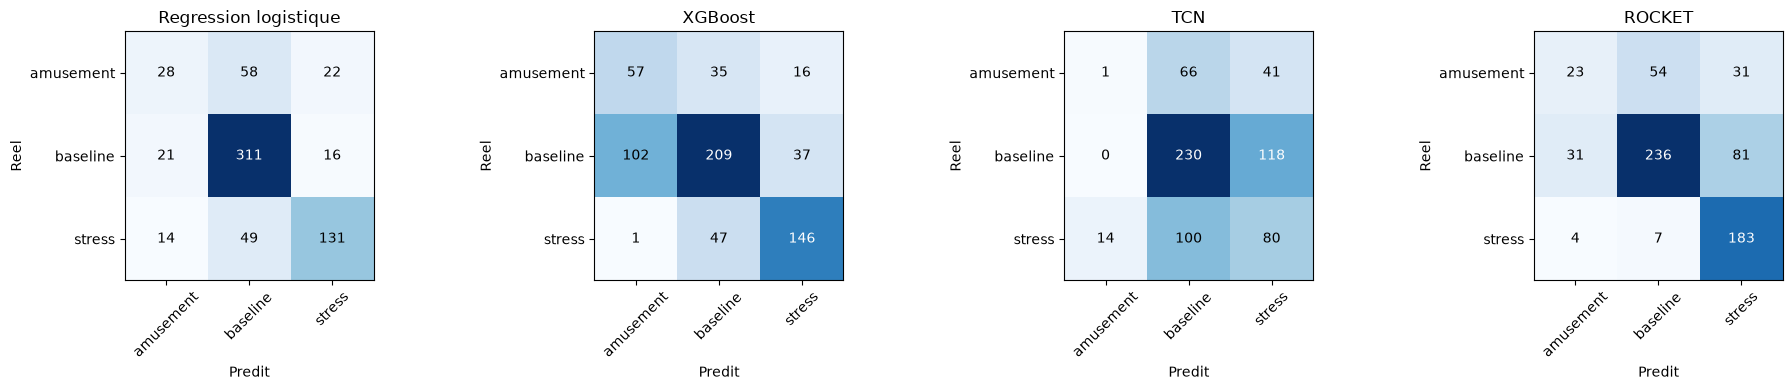

In [27]:
# --- Matrices de confusion des 4 modeles compares ---
labels_order = sorted(windows_df["condition"].unique())
all_models_preds = [
    ("Regression logistique", y_pred_lr),
    ("XGBoost", y_pred_xgb),
    ("TCN", y_pred_tcn),
    ("ROCKET", y_pred_rocket),
]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (name, y_pred) in zip(axes, all_models_preds):
    cm = confusion_matrix(y_test, y_pred, labels=labels_order)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels_order))); ax.set_xticklabels(labels_order, rotation=45)
    ax.set_yticks(range(len(labels_order))); ax.set_yticklabels(labels_order)
    ax.set_xlabel("Predit"); ax.set_ylabel("Reel"); ax.set_title(name)
    for i in range(len(labels_order)):
        for j in range(len(labels_order)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("fig_confusion_matrices.png", dpi=120)
plt.show()


,accuracy,f1_macro
modele,,
Regression logistique,0.723077,0.620420
XGBoost,0.633846,0.607508
TCN,0.478462,0.334685
ROCKET,0.680000,0.585786


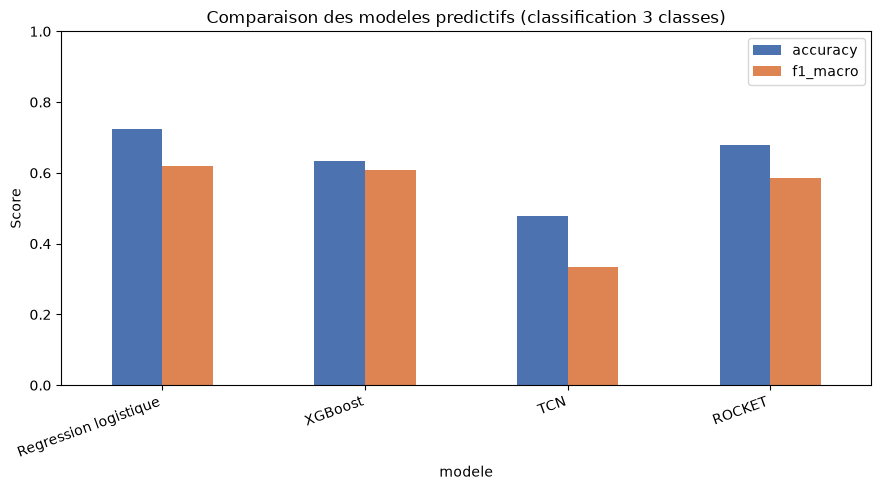

In [28]:
# --- Graphique de comparaison des modeles (exactitude et F1 macro) ---
comparison_rows = []
for name, y_pred in all_models_preds:
    comparison_rows.append({
        "modele": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
    })
comparison_df = pd.DataFrame(comparison_rows).set_index("modele")
display(comparison_df)

ax = comparison_df.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Comparaison des modeles predictifs (classification 3 classes)")
ax.set_xticklabels(comparison_df.index, rotation=20, ha="right")
plt.tight_layout()
plt.savefig("fig2_comparaison_modeles.png", dpi=120)
plt.show()


**Interprétation (mise à jour après correction du split + ajout de ROCKET, retour prof) :** une fois
l'évaluation correctement isolée par sujet (Q3.1), le classement sur le test (3 sujets jamais vus) est :

| Modèle | Exactitude | F1 macro |
|---|---|---|
| Régression logistique | 0.723 | 0.620 |
| **ROCKET** | **0.680** | **0.586** |
| XGBoost | 0.634 | 0.608 |
| TCN | 0.478 | 0.335 |

La régression logistique et XGBoost distinguent raisonnablement `stress` des deux autres conditions, tandis que
`baseline` et `amusement` restent plus souvent confondus entre eux (voir les matrices de confusion ci-dessus).

**ROCKET (voir Question 3.3, complément) confirme l'hypothèse posée par le retour du prof :** c'est un
algorithme nativement temporel (il reçoit la séquence brute, comme le TCN, pas des statistiques résumées) et
pourtant **classique** (les noyaux convolutionnels sont aléatoires et fixes, seul un classifieur linéaire est
appris) — il bat nettement le TCN (0.680 contre 0.478) tout en restant compétitif avec les modèles tabulaires
classiques. Ceci confirme que le problème du TCN n'était pas "les réseaux de neurones sont mauvais pour ces
données", mais bien le **nombre insuffisant de sujets (~9) pour apprendre des dizaines de milliers de poids par
rétropropagation** : un algorithme temporel qui n'a presque rien à apprendre par gradient (ROCKET) généralise
beaucoup mieux dans ce régime de données limité.

Le TCN, lui, **sur-apprend très rapidement** : sa perte de validation est déjà minimale dès la 1ère époque et
ne fait ensuite qu'augmenter (voir la courbe d'apprentissage, Question 3.3). Ce n'était pas visible dans
l'ancienne version du notebook, où le test était consulté à chaque époque (fuite implicite) et où le split
laissait fuiter de l'information entre sujets — les deux problèmes masquaient un sur-apprentissage réel. C'est
un résultat honnête et utile en soi : il montre concrètement pourquoi corriger la fuite de sujets et la fuite
de validation (Q1/Q3.1/Q3.3), puis adapter le choix d'algorithme à la taille réelle des données (ROCKET plutôt
qu'un TCN pleinement appris), change la conclusion — et pas seulement les chiffres.


### 3.4 Évaluation rigoureuse et limites de la prédiction (3 + 2 points)

**Évaluation :** on utilise l'exactitude et le F1 macro (qui pondère également chaque classe, important ici
car les classes ne sont pas parfaitement équilibrées — la condition `baseline` dure plus longtemps que
`amusement`), ainsi que les matrices de confusion complètes pour voir quelles conditions sont confondues entre
elles (typiquement, `amusement` et `baseline` sont souvent plus proches physiologiquement que `stress`, qui a
tendance à se distinguer plus nettement). On complète l'évaluation par sujet (Q3.1) par une validation croisée
`GroupKFold` par sujet (Q3.2), qui donne une moyenne et un écart-type sur 5 répartitions différentes des 15
sujets plutôt qu'une seule.

**Limites de la prédiction (à ne pas confondre avec la partie causale) :**
- Une bonne performance de classification montre que le signal physiologique **contient de l'information**
  discriminante entre les conditions, mais ne dit rien sur ce qui **causerait** un changement physiologique :
  le modèle pourrait très bien s'appuyer sur des artefacts de mouvement corrélés au protocole (ex. les sujets
  bougent différemment pendant l'amusement) plutôt que sur un mécanisme physiologique du stress en tant que tel.
- **Correction (retour prof) :** la version précédente de ce notebook séparait train/test *chronologiquement à
  l'intérieur de chaque sujet* — un même sujet apparaissait donc des deux côtés (fuite entre sujets), et comme
  `baseline` est toujours en tout début de session, le test (les fenêtres les plus tardives) ne contenait
  **aucune** fenêtre baseline (0%), rendant l'évaluation à 3 classes non représentative. Le split est désormais
  fait **par sujet entier** (Q3.1) : plus aucun sujet n'est partagé entre train/validation/test, et le test
  contient bien les 3 conditions puisqu'il est composé de sujets complets. La validation croisée `GroupKFold`
  (Q3.2) confirme que la performance ne dépend pas d'un choix particulier de 3 sujets de test.
- Il reste malgré tout une limite fondamentale : avec seulement 15 sujets, un split par sujet en train/val/test
  laisse peu de sujets de test (~3) — une évaluation *leave-one-subject-out* complète (15 plis, un par sujet)
  donnerait une estimation encore plus stable de la généralisation inter-sujets, mais représente un coût de
  calcul plus élevé (surtout pour le TCN) et sort du cadre de ce projet.


---
## Question 4 — Formulation de la question causale (15 points)

### 4.0 Traitement, sortie et variables d'ajustement

**Traitement D :** être dans la condition **stress** pendant la fenêtre temporelle courante (indicatrice
binaire, `D = 1` si `condition == "stress"`, `D = 0` sinon — regroupe `baseline` et `amusement` comme
"non-stress").

**Sortie causale Y :** `eda_mean_next`, l'activité électrodermale moyenne de la **fenêtre suivante** (10
secondes plus tard), déjà construite en Question 2.4. On choisit l'EDA car c'est le marqueur physiologique le
plus directement relié à l'activation du système nerveux sympathique (contrairement à l'ECG ou la
température, plus sujets à des artefacts de mouvement ou de dérive lente).

**Variables d'ajustement X :**
- `eda_mean_prev` — l'EDA moyenne de la fenêtre *précédant* la fenêtre de traitement (état physiologique de
  base, avant l'exposition au stress de la fenêtre courante). **Important :** on utilise l'EDA de la fenêtre
  précédente et non celle de la fenêtre courante, car l'EDA courante est mesurée *pendant* la condition
  stress elle-même — l'utiliser comme covariable reviendrait à ajuster sur une conséquence du traitement (un
  médiateur), ce qui biaiserait l'estimation au lieu de la corriger.
- `acc_norm_mean_prev` — le mouvement pendant la fenêtre **précédant** la fenêtre de traitement.
  **Correction (retour prof) :** la version précédente utilisait `acc_norm_mean` de la fenêtre courante,
  présentée comme un confondant classique. Mais ce mouvement est mesuré *pendant* la fenêtre de traitement
  elle-même : il peut très bien être une **conséquence** du stress (on bouge différemment quand on est
  stressé) plutôt qu'une cause commune de D et Y — l'ajuster reviendrait, comme pour l'EDA, à contrôler un
  médiateur/une variable post-traitement, ce qui biaise l'estimation au lieu de la corriger. On utilise donc,
  par cohérence avec `eda_mean_prev`, le mouvement de la fenêtre **précédente** (pré-traitement), qui reflète
  une tendance individuelle au mouvement sans pouvoir être une conséquence du traitement de la fenêtre courante.
- `t_since_start_s` — le temps écoulé depuis le début de l'enregistrement, pour ne pas confondre un effet
  temporel du protocole (dérive du capteur, fatigue, ordre fixe baseline → stress → amusement) avec un
  véritable effet causal du stress. **Point de vigilance (retour prof) :** le protocole impose un ordre
  largement fixe des conditions, donc `t_since_start_s` détermine en grande partie `D` — un problème de
  **positivité** potentiel (voir Question 4.1 et le contrôle de recouvrement ajouté en Question 5.1). On
  restreint désormais l'analyse au support commun de `t_since_start_s` entre les fenêtres stress et non-stress.
- `subject` — utilisé pour étudier l'**hétérogénéité** de l'effet entre sujets (Question 5), pas comme
  covariable numérique brute dans le modèle.

**Question causale précise :** *Quel est l'effet moyen d'être en condition de stress (plutôt que baseline ou
amusement) pendant une fenêtre de 10 secondes sur l'activité électrodermale moyenne de la fenêtre suivante,
après ajustement sur l'état électrodermal préalable, le niveau de mouvement préalable et le temps écoulé
depuis le début du protocole ?*

### 4.1 DAG et hypothèses (4 points)


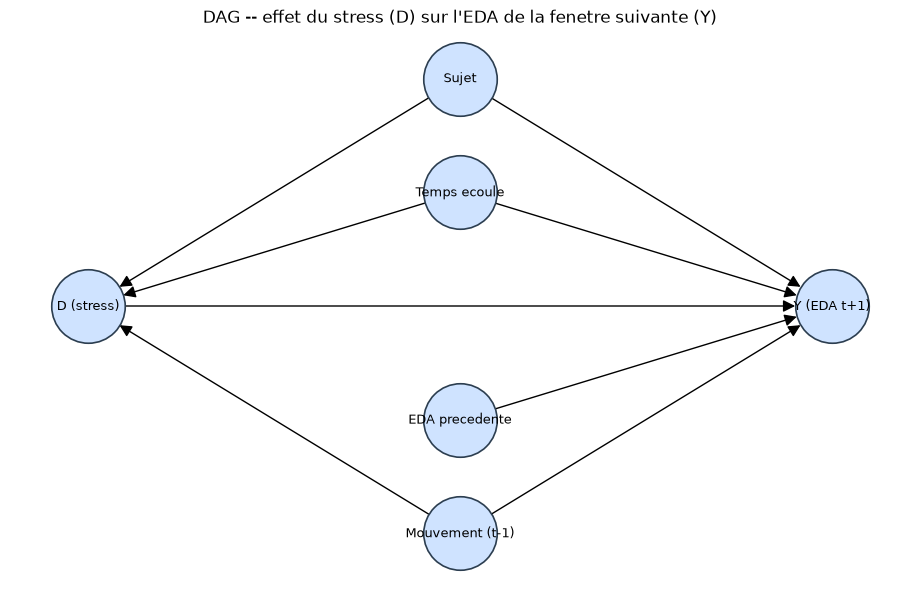

In [29]:
import networkx as nx

dag = nx.DiGraph()
edges = [
    ("Sujet", "D (stress)"),              # certains sujets reagissent plus/moins au protocole (trait individuel)
    ("Sujet", "Y (EDA t+1)"),             # niveau d'activite electrodermale de base variable selon la physiologie
    ("Temps ecoule", "D (stress)"),       # le protocole impose l'ordre fixe baseline -> stress -> amusement
    ("Temps ecoule", "Y (EDA t+1)"),      # derive lente du capteur / fatigue au fil de la session
    ("EDA precedente", "Y (EDA t+1)"),    # autocorrelation naturelle d'un signal physiologique dans le temps
    ("Mouvement (t-1)", "D (stress)"),    # tendance individuelle au mouvement, mesuree AVANT le traitement
    ("Mouvement (t-1)", "Y (EDA t+1)"),   # cette meme tendance peut aussi affecter l'EDA independamment du stress
    ("D (stress)", "Y (EDA t+1)"),        # effet causal d'interet (fleche que l'on cherche a estimer)
]
dag.add_edges_from(edges)

pos = {
    "D (stress)": (0, 0),
    "Y (EDA t+1)": (2.2, 0),
    "Sujet": (1.1, 1.4),
    "Temps ecoule": (1.1, 0.7),
    "EDA precedente": (1.1, -0.7),
    "Mouvement (t-1)": (1.1, -1.4),
}
plt.figure(figsize=(9, 5.5))
nx.draw(dag, pos, with_labels=True, node_color="#cfe3ff", node_size=2800, font_size=9,
        arrowsize=18, edgecolors="#2c3e50", linewidths=1.2)
plt.title("DAG -- effet du stress (D) sur l'EDA de la fenetre suivante (Y)")
plt.savefig("fig_dag.png", dpi=120, bbox_inches="tight")
plt.show()


**Hypothèses nécessaires pour interpréter l'effet estimé comme causal :**
- **Échangeabilité conditionnelle (ignorabilité) :** une fois ajusté sur l'EDA précédente, le mouvement
  précédent et le temps écoulé, il ne reste pas d'autre facteur qui influencerait à la fois la probabilité
  d'être en stress et l'EDA future. C'est une hypothèse forte ici : le protocole étant en ordre fixe (jamais
  assigné aléatoirement), des facteurs non observés (caféine, anxiété de trait, ordre exact des tâches)
  pourraient encore biaiser l'estimation — limite discutée en Question 6.
- **Positivité :** chaque combinaison de valeurs des covariables X doit avoir une probabilité non nulle
  d'être observée aussi bien en stress qu'en non-stress. **Point sensible (retour prof) :** le protocole étant
  en grande partie séquentiel (baseline puis stress/amusement dans un ordre largement fixe), `t_since_start_s`
  est fortement associé à `D` — le recouvrement entre groupes stress/non-stress peut être faible ou nul à
  certains instants du protocole. On vérifie donc explicitement (Question 5.1) le support commun de
  `t_since_start_s` entre les deux groupes, et on restreint l'analyse à ce support commun (trimming) plutôt que
  de supposer la positivité vérifiée sans la contrôler.
- **Cohérence :** la valeur de Y observée sous le traitement reçu correspond bien à Y(D=1) — raisonnable ici
  car le traitement (être en condition stress) est une définition claire et binaire, sans versions multiples
  ambiguës du "traitement".
- **Absence de fuite temporelle :** Y est mesurée strictement dans la fenêtre *suivante* la fenêtre de
  traitement, et `eda_mean_prev`/`acc_norm_mean_prev` sont mesurées strictement *avant* — aucune variable
  utilisée ne provient du futur par rapport au moment où elle est censée être connue. On vérifie de plus
  (Question 2.4/5.0) que les fenêtres "précédente"/"suivante" sont bien directement adjacentes dans le temps
  (`window_id` consécutifs), et non simplement des lignes voisines dans le tableau.


---
## Question 5 — Estimation causale avec arbres causaux et méthodes comparatives (20 points)

### 5.0 Préparation des données pour l'analyse causale

In [30]:
# --- EDA/mouvement precedents (pre-traitement) + EDA suivante (sortie), et indicatrice de traitement ---
windows_df = windows_df.sort_values(["subject", "window_id"]).reset_index(drop=True)

# Correction (retour prof) : meme verification de contiguite que Q2.4 (decalage vers l'avant),
# appliquee ici au decalage vers l'arriere (fenetre precedente) -- deux lignes consecutives du
# DataFrame ne sont pas forcement des fenetres temporellement adjacentes (fenetres de transition
# deja retirees). On ne garde le decalage que si window_id_prev == window_id - 1.
windows_df["window_id_prev"] = windows_df.groupby("subject")["window_id"].shift(1)
is_contiguous_prev = windows_df["window_id_prev"] == windows_df["window_id"] - 1

# Correction (retour prof) : acc_norm_mean_prev (fenetre PRECEDENTE) remplace acc_norm_mean
# (fenetre courante) comme covariable -- l'ancienne version mesurait le mouvement PENDANT la
# fenetre de traitement, ce qui peut etre une consequence du stress (mediateur) plutot qu'un
# confondant pre-traitement ; l'ajuster dessus biaiserait l'estimation au lieu de la corriger
# (meme raisonnement que pour eda_mean_prev, deja applique dans la version precedente du notebook).
prev_shift_cols = ["eda_mean", "acc_norm_mean"]
for col in prev_shift_cols:
    shifted = windows_df.groupby("subject")[col].shift(1)
    windows_df[f"{col}_prev"] = shifted.where(is_contiguous_prev)
# eda_mean_next a deja ete cree (et verifiee pour la contiguite) en Question 2.4

causal_cols = ["subject", "window_id", "condition", "eda_mean_prev", "eda_mean_next",
               "acc_norm_mean_prev", "t_since_start_s"]
causal_df = windows_df.dropna(subset=["eda_mean_prev", "eda_mean_next", "acc_norm_mean_prev"])[causal_cols].reset_index(drop=True)
causal_df["D_stress"] = (causal_df["condition"] == "stress").astype(int)

print("Fenetres utilisables pour l'analyse causale :", len(causal_df))
print("Proportion en condition stress (traitement) :", round(causal_df["D_stress"].mean(), 3))
causal_df.describe().T[["mean", "std", "min", "max"]].round(3)


Fenetres utilisables pour l'analyse causale : 3185
Proportion en condition stress (traitement) : 0.299


,mean,std,min,max
subject,9.409,4.705,2.000,17.000
window_id,185.689,140.120,4.000,590.000
eda_mean_prev,4.595,3.444,0.560,19.994
eda_mean_next,4.597,3.450,0.560,20.250
acc_norm_mean_prev,0.930,0.017,0.902,1.036
t_since_start_s,1856.895,1401.199,40.000,5900.000
D_stress,0.299,0.458,0.000,1.000


### 5.1 Effet moyen du traitement — régression ajustée (5 points)

In [31]:
import statsmodels.api as sm

# --- Diagnostic de positivite et restriction au support commun (correction retour prof) ---
# t_since_start_s est fortement associe a D_stress (ordre du protocole largement fixe) : on
# verifie donc le recouvrement de son support entre les fenetres stress et non-stress, et on
# restreint l'analyse a ce support commun (trimming) -- pratique standard pour attenuer une
# violation de positivite plutot que de simplement l'ignorer.
t_min_common = max(causal_df.loc[causal_df["D_stress"] == 0, "t_since_start_s"].min(),
                    causal_df.loc[causal_df["D_stress"] == 1, "t_since_start_s"].min())
t_max_common = min(causal_df.loc[causal_df["D_stress"] == 0, "t_since_start_s"].max(),
                    causal_df.loc[causal_df["D_stress"] == 1, "t_since_start_s"].max())
n_before_trim = len(causal_df)
causal_df = causal_df[causal_df["t_since_start_s"].between(t_min_common, t_max_common)].reset_index(drop=True)
print(f"Support commun de t_since_start_s (stress ET non-stress observes) : "
      f"[{t_min_common:.1f}, {t_max_common:.1f}] s")
print(f"Fenetres conservees apres restriction au support commun : {len(causal_df)} / {n_before_trim}")

X_reg = causal_df[["D_stress", "eda_mean_prev", "acc_norm_mean_prev", "t_since_start_s"]].copy()
X_reg = sm.add_constant(X_reg)  # ajoute l'intercept (terme constant) au modele lineaire
y_reg = causal_df["eda_mean_next"]

ols_model = sm.OLS(y_reg, X_reg).fit()
print(ols_model.summary())

# Le coefficient de D_stress s'interprete comme l'effet moyen (ATE) du stress sur l'EDA de la
# fenetre suivante, "toutes choses egales par ailleurs" (a EDA precedente, mouvement precedent et
# temps ecoule fixes) -- sous l'hypothese d'echangeabilite conditionnelle discutee en Q4.1, et sur
# le support commun de t_since_start_s defini ci-dessus.
ate_regression = ols_model.params["D_stress"]
ate_regression_ci = ols_model.conf_int().loc["D_stress"]
print(f"\nEffet moyen ajuste du stress sur l'EDA de la fenetre suivante : {ate_regression:.4f}")
print(f"Intervalle de confiance 95% : [{ate_regression_ci[0]:.4f}, {ate_regression_ci[1]:.4f}]")

# --- Explication de la fonction mathematique utilisee ci-dessus ---
# OLS (moindres carres ordinaires) : trouve les coefficients beta qui minimisent la somme des
#   carres des ecarts entre les valeurs observees de Y et les valeurs predites par la
#   combinaison lineaire des variables explicatives (min sur beta de la somme des (y - X*beta)^2).


Support commun de t_since_start_s (stress ET non-stress observes) : [1890.0, 4220.0] s
Fenetres conservees apres restriction au support commun : 1106 / 3185
                            OLS Regression Results                            
Dep. Variable:          eda_mean_next   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                 9.083e+04
Date:                Sat, 29 Aug 2026   Prob (F-statistic):               0.00
Time:                        00:54:33   Log-Likelihood:                 123.79
No. Observations:                1106   AIC:                            -237.6
Df Residuals:                    1101   BIC:                            -212.5
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t  

### 5.2 Forêt causale — effets hétérogènes (6 points)

La régression ajustée ci-dessus donne un effet moyen unique pour tous les sujets. Une **forêt causale**
(`CausalForestDML`, econml) permet d'estimer un effet individuel par fenêtre, potentiellement différent selon
l'état physiologique de base, le niveau de mouvement et le temps écoulé — donc de détecter une
**hétérogénéité** de l'effet du stress que la régression linéaire ne peut pas capturer.

**Choix des modèles de nuisance :** `CausalForestDML` est une méthode de double apprentissage machine (DML) :
avant d'estimer l'effet causal, elle doit d'abord modéliser `E[Y|X]` et `E[D|X]` ("modèles de nuisance"). Ici,
ces modèles de nuisance sont des **gradient boosting (XGBoost)**, qui capturent bien des relations non
linéaires entre les covariables d'ajustement et le traitement/la sortie avec peu de variance, ce qui réduit
le biais de l'effet causal estimé au second stage — un ajustement de bonne qualité au premier stage se
traduit directement par une estimation causale plus fiable.


In [32]:
from econml.dml import CausalForestDML
from xgboost import XGBRegressor, XGBClassifier as XGBClassifierNuisance

X_het = causal_df[["eda_mean_prev", "acc_norm_mean_prev", "t_since_start_s"]].values
T_causal = causal_df["D_stress"].values
Y_causal = causal_df["eda_mean_next"].values

causal_forest = CausalForestDML(
    model_y=XGBRegressor(   # modele de nuisance E[Y|X] : regression, car Y (EDA future) est continue
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1,
    ),
    model_t=XGBClassifierNuisance(   # modele de nuisance E[D|X] : classification, car D (stress) est binaire
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1,
        eval_metric="logloss",
    ),
    discrete_treatment=True,   # le traitement D est une indicatrice binaire (stress vs non-stress)
    n_estimators=500,          # nombre d'arbres de la foret causale (eleve pour stabiliser l'ITE estime)
    min_samples_leaf=10,       # au moins 10 fenetres par feuille -> evite des effets individuels
                                # estimes sur trop peu d'observations (donc trop bruites)
    random_state=RANDOM_STATE,
)
causal_forest.fit(Y_causal, T_causal, X=X_het)

ite = causal_forest.effect(X_het)  # effet individuel estime (ITE) pour chaque fenetre
ite_lb, ite_ub = causal_forest.effect_interval(X_het, alpha=0.05)  # intervalle de confiance a 95% par fenetre
causal_df["ite_estime"] = ite
causal_df["ite_lb"] = ite_lb
causal_df["ite_ub"] = ite_ub

print("Effet moyen estime par la foret causale (ATE) :", round(ite.mean(), 4))
print(causal_forest.ate_inference(X_het).summary())

# --- Explication de la fonction mathematique utilisee ci-dessus ---
# CausalForestDML (foret causale, double machine learning) : estime d'abord deux modeles de
#   nuisance, E[Y|X] et E[D|X], pour retirer l'effet des covariables X, puis ajuste une foret
#   d'arbres sur les residus pour estimer un effet du traitement (ITE) propre a chaque
#   observation, plutot qu'un effet moyen unique.


Effet moyen estime par la foret causale (ATE) : -0.0134


               Uncertainty of Mean Point Estimate               
mean_point stderr_mean zstat  pvalue ci_mean_lower ci_mean_upper
----------------------------------------------------------------
    -0.013        0.38 -0.035  0.972        -0.758         0.732
      Distribution of Point Estimate     
std_point pct_point_lower pct_point_upper
-----------------------------------------
    0.351          -0.947           0.657
     Total Variance of Point Estimate     
stderr_point ci_point_lower ci_point_upper
------------------------------------------
       0.517         -1.168          0.959
------------------------------------------

Note: The stderr_mean is a conservative upper bound.


**Hétérogénéité par sujet, par mouvement et par état physiologique initial** (figure obligatoire de la
Question 6 sur les effets causaux) :

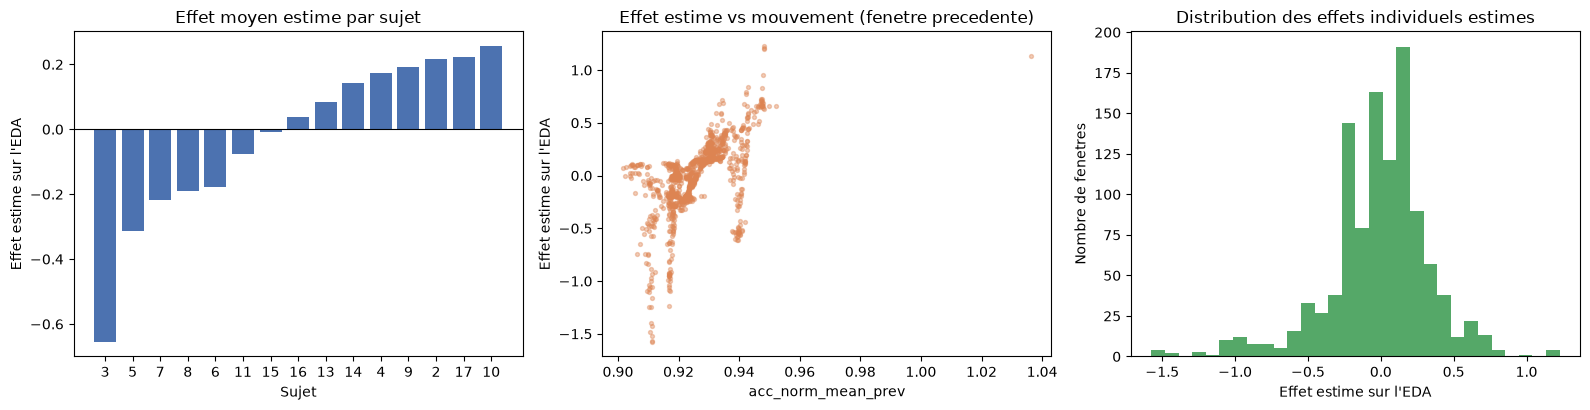

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ite_by_subject = causal_df.groupby("subject")["ite_estime"].mean().sort_values()
axes[0].bar(ite_by_subject.index.astype(str), ite_by_subject.values, color="#4C72B0")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Effet moyen estime par sujet")
axes[0].set_xlabel("Sujet"); axes[0].set_ylabel("Effet estime sur l'EDA")

axes[1].scatter(causal_df["acc_norm_mean_prev"], causal_df["ite_estime"], s=8, alpha=0.4, color="#DD8452")
axes[1].set_title("Effet estime vs mouvement (fenetre precedente)")
axes[1].set_xlabel("acc_norm_mean_prev"); axes[1].set_ylabel("Effet estime sur l'EDA")

axes[2].hist(causal_df["ite_estime"], bins=30, color="#55A868")
axes[2].set_title("Distribution des effets individuels estimes")
axes[2].set_xlabel("Effet estime sur l'EDA"); axes[2].set_ylabel("Nombre de fenetres")

plt.tight_layout()
plt.savefig("fig3_effets_causaux.png", dpi=120)
plt.show()


### 5.3 Comparaison avec le TCN (4 points)

Les modèles prédictifs de la Question 3 (en particulier la régression logistique, XGBoost et ROCKET, qui
généralisent mieux que le TCN sur des sujets jamais vus — voir Question 3.3bis) montrent qu'on peut **reconnaître** la
condition stress à partir du signal physiologique de la fenêtre courante avec une exactitude modeste mais
réelle — c'est une tâche purement prédictive : le modèle peut s'appuyer sur n'importe quelle corrélation utile
(y compris des artefacts de mouvement liés au protocole, ou la "signature" propre à chaque sujet) sans se
soucier de savoir si cette corrélation reflète un mécanisme causal. La forêt causale répond à une question
différente et plus stricte : après avoir **retiré** statistiquement l'effet des covariables observées (état
EDA préalable, mouvement préalable, temps écoulé), reste-t-il un effet du stress sur l'EDA de la fenêtre
suivante ? Une classification précise (quel que soit le modèle qui l'obtient) ne garantit donc en rien qu'il
existe un effet causal détectable une fois ces facteurs ajustés — et inversement, un effet causal modeste
n'empêche pas une classification correcte, car un modèle prédictif exploite bien plus d'information (toute la
forme du signal, la signature du sujet) que les seules covariables pré-traitement utilisées pour l'ajustement
causal.


### 5.4 Incertitude et limites (3 + 2 points)

- Les intervalles de confiance de la régression ajustée et de la forêt causale (`ate_inference`) donnent une
  fourchette plausible de l'effet moyen plutôt qu'une valeur ponctuelle unique — un intervalle qui contient 0
  signifierait qu'on ne peut pas conclure à un effet causal moyen détectable avec ces données et ces
  covariables.
- La distribution des effets individuels estimés (histogramme ci-dessus) donne une idée de l'hétérogénéité,
  mais chaque effet individuel est lui-même estimé avec bruit — les valeurs extrêmes de cette distribution
  ne doivent pas être sur-interprétées comme des effets individuels certains.
- Limite principale : l'hypothèse d'échangeabilité conditionnelle n'est pas testable directement avec ces
  données — elle repose sur l'hypothèse qu'`eda_mean_prev`, `acc_norm_mean` et `t_since_start_s` suffisent à
  capturer les différences pertinentes entre fenêtres en stress et hors stress, ce qui reste une hypothèse
  de travail plutôt qu'un fait vérifié.

---
## Question 6 — Interprétation, conclusion et qualité du notebook (15 points)

### 6.0 Figure — série temporelle physiologique (figure obligatoire)

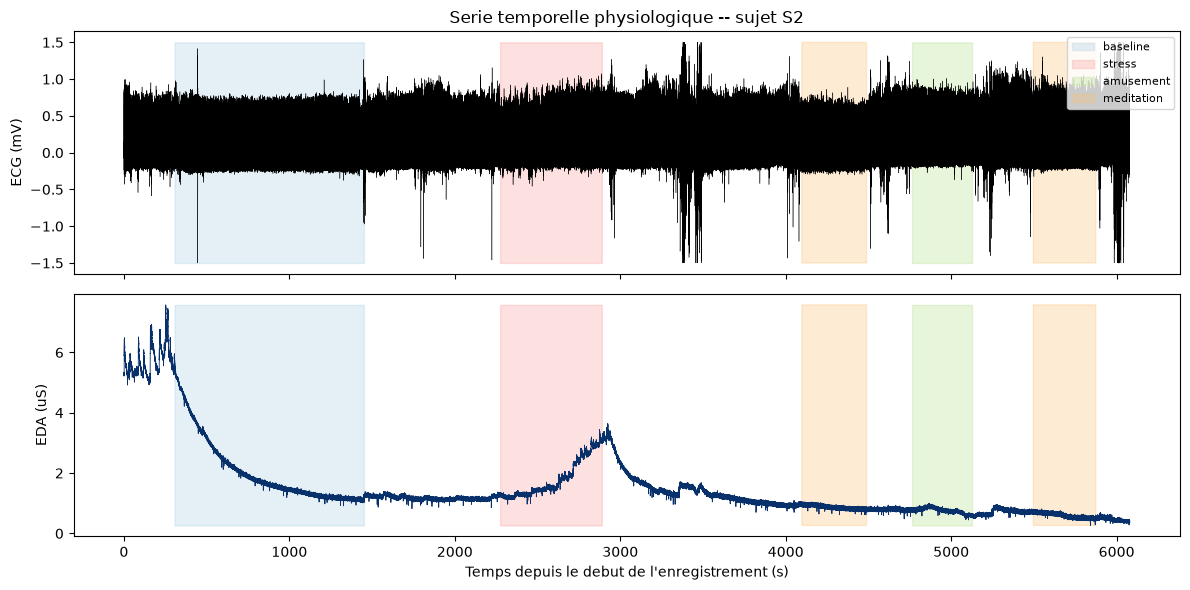

In [34]:
# --- Figure obligatoire : serie temporelle physiologique (ECG et EDA) pour un sujet, avec les conditions ---
FIG_SUBJECT = SUBJECTS[0]
d_fig = raw_data[FIG_SUBJECT]
ecg_fig = d_fig["signal"]["chest"]["ECG"].flatten()
eda_fig = d_fig["signal"]["chest"]["EDA"].flatten()
label_fig = d_fig["label"].flatten()
t_fig = np.arange(len(ecg_fig)) / FREQ_CHEST

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
cond_colors = {1: "#a6cee3", 2: "#fb9a99", 3: "#b2df8a", 4: "#fdbf6f"}

for code_, color in cond_colors.items():
    mask = label_fig == code_
    if mask.any():
        axes[0].fill_between(t_fig, ecg_fig.min(), ecg_fig.max(), where=mask,
                              color=color, alpha=0.3, label=LABEL_MAP[code_])
axes[0].plot(t_fig, ecg_fig, color="black", linewidth=0.3)
axes[0].set_ylabel("ECG (mV)")
axes[0].set_title(f"Serie temporelle physiologique -- sujet S{FIG_SUBJECT}")
axes[0].legend(loc="upper right", fontsize=8)

for code_, color in cond_colors.items():
    mask = label_fig == code_
    if mask.any():
        axes[1].fill_between(t_fig, eda_fig.min(), eda_fig.max(), where=mask, color=color, alpha=0.3)
axes[1].plot(t_fig, eda_fig, color="#08306b", linewidth=0.6)
axes[1].set_ylabel("EDA (uS)")
axes[1].set_xlabel("Temps depuis le debut de l'enregistrement (s)")

plt.tight_layout()
plt.savefig("fig1_serie_temporelle.png", dpi=120)
plt.show()

### 6.1 Interprétation prédictive vs causale (5 points)

- **Volet prédictif (Question 3) :** une fois le split corrigé pour ne plus fuiter d'information entre
  sujets (retour prof, Q1/Q3.1), les modèles classiques (régression logistique, XGBoost) et ROCKET (algorithme temporel
  classique, voir Question 3.3) montrent que le
  signal physiologique contient une information discriminante réelle mais modeste entre `baseline`, `stress`
  et `amusement` (exactitude ~0.6-0.7 sur des sujets jamais vus) — la condition `stress` est généralement la
  mieux reconnue, tandis que `baseline` et `amusement` sont plus souvent confondues entre elles. Le TCN, lui,
  sur-apprend fortement avec seulement ~9 sujets d'entraînement et généralise moins bien que tous les autres
  modèles une fois évalué correctement (voir Question 3.3bis) : plus de paramètres n'aide pas ici, faute
  de sujets suffisamment nombreux pour les contraindre — ROCKET (temporel, mais avec très peu de poids
  appris) confirme que le problème vient de la taille des données, pas de la nature temporelle du signal.
- **Volet causal (Questions 4-5) :** la régression ajustée et la forêt causale répondent à une question
  différente — non pas "peut-on reconnaître le stress ?" mais "le fait d'être en stress **cause-t-il** un
  changement mesurable de l'EDA dans la fenêtre suivante, une fois les facteurs observés (y compris
  pré-traitement, pas contemporains — retour prof Q4/Q5) pris en compte ?". Une bonne performance prédictive
  (Q3) ne prouve **pas** l'existence de cet effet causal, et un effet causal significatif ne garantirait pas
  non plus une classification parfaite — ce sont deux questions complémentaires mais distinctes, comme demandé
  par l'énoncé.
- Le signe et l'amplitude de l'effet estimé (Q5.1/5.2), ainsi que l'hétérogénéité observée par sujet et selon
  le mouvement (Q5.2), permettent d'aller au-delà d'un simple "le stress a un effet" pour discuter *pour qui*
  et *dans quelles conditions* cet effet semble le plus marqué.
